# An Interpretable Clinical Hematological Signature-Based Machine Learning Framework for Dengue Detection Using CBC Parameters

**Proposed Methodology: D-CHSS (Dengue Clinical Hematological Signature Score)**

D-CHSS combines three hematological components derived from CBC reference-range deviations:
- Thrombocytopenia Score (TS)
- Leukocyte Response Score (LS)
- Hemoconcentration Score (HS)

Additionally, literature-supported hematological ratios (NLR, PLR, LMR, etc.) are engineered
from existing CBC columns to strengthen the predictive feature set. Component weights are
learned from training data only (no manual weights, no data leakage).

**Objective:** Determine whether a clinically interpretable hematological signature improves
dengue detection compared to raw CBC features alone.

**Disclaimer:** This is a research notebook, not a medical diagnostic tool.

In [51]:
import sys, subprocess

def install_if_missing(pkg):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

install_if_missing("xgboost")
install_if_missing("shap")
install_if_missing("statsmodels")

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                      RandomizedSearchCV, cross_val_score, cross_val_predict)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, matthews_corrcoef,
                              confusion_matrix, roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve

from scipy.stats import mannwhitneyu, spearmanr

import xgboost as xgb
import shap

from statsmodels.stats.contingency_tables import mcnemar

import pickle

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [52]:
DATA_PATH = "/kaggle/input/datasets/musabbir22/dengue-detection-dataset4/Dengue Fever Hematological Dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns.tolist())
df.head()

Dataset Shape: (1523, 19)

Column Names:
 ['Gender', 'Age', 'Hemoglobin(g/dl)', 'Neutrophils(%)', 'Lymphocytes(%)', 'Monocytes(%)', 'Eosinophils(%)', 'RBC', 'HCT(%)', 'MCV(fl)', 'MCH(pg)', 'MCHC(g/dl)', 'RDW-CV(%)', 'Total Platelet Count(/cumm)', 'MPV(fl)', 'PDW(%)', 'PCT(%)', 'Total WBC count(/cumm)', 'Result']


,Gender,Age,Hemoglobin(g/dl),Neutrophils(%),Lymphocytes(%),Monocytes(%),Eosinophils(%),RBC,HCT(%),MCV(fl),MCH(pg),MCHC(g/dl),RDW-CV(%),Total Platelet Count(/cumm),MPV(fl),PDW(%),PCT(%),Total WBC count(/cumm),Result
0,Male,21,14.8,48,47,3,2,5,48.00,96.0,29.60,30.8,11.6,112000,10.70,15.40,0.120,5100,positive
1,Male,30,15.0,47,49,6,3,5,49.80,96.1,28.40,29.5,11.8,96000,10.60,15.80,0.121,4500,positive
2,Male,51,16.3,41,48,4,5,5,50.10,93.5,31.30,32.7,13.5,184000,10.40,16.40,0.130,6000,negative
3,Female,26,12.3,46,49,7,5,5,44.00,90.0,30.50,30.5,14.7,167000,8.10,17.10,0.110,5000,negative
4,Male,35,16.1,45,46,4,4,5,50.53,91.0,29.12,29.2,15.2,155000,10.52,12.34,0.150,4600,negative


In [53]:
gender_col_raw = [c for c in df.columns if 'gender' in c.lower() or 'sex' in c.lower()]
result_col_raw = [c for c in df.columns if 'result' in c.lower() or 'dengue' in c.lower()
                   or 'outcome' in c.lower() or 'diagnosis' in c.lower()]

print("Detected Gender column(s):", gender_col_raw)
print("Detected Result column(s):", result_col_raw)

if gender_col_raw:
    print("\nUnique values in Gender column:", df[gender_col_raw[0]].unique())

if result_col_raw:
    print("Unique values in Result column:", df[result_col_raw[0]].unique())

Detected Gender column(s): ['Gender']
Detected Result column(s): ['Result']

Unique values in Gender column: ['Male' 'Female']
Unique values in Result column: ['positive' 'negative']


## Column Mapping and Target/Gender Encoding
Mapping actual CSV column names to clean internal names, and encoding Gender/Result
based on their actual unique values (not assumed).

In [54]:
def map_columns(columns):
    colmap = {}
    for col in columns:
        c = col.lower().strip()
        if c == 'age' or c.startswith('age'):
            colmap[col] = 'age'
        elif 'gender' in c or 'sex' in c:
            colmap[col] = 'gender'
        elif 'hemoglobin' in c:
            colmap[col] = 'hemoglobin'
        elif 'neutrophil' in c:
            colmap[col] = 'neutrophils'
        elif 'lymphocyte' in c:
            colmap[col] = 'lymphocytes'
        elif 'monocyte' in c:
            colmap[col] = 'monocytes'
        elif 'eosinophil' in c:
            colmap[col] = 'eosinophils'
        elif 'rbc' in c:
            colmap[col] = 'rbc'
        elif 'hct' in c or 'hematocrit' in c:
            colmap[col] = 'hct'
        elif 'mcv' in c:
            colmap[col] = 'mcv'
        elif 'mchc' in c:
            colmap[col] = 'mchc'
        elif 'mch' in c:
            colmap[col] = 'mch'
        elif 'rdw' in c:
            colmap[col] = 'rdw_cv'
        elif 'platelet' in c:
            colmap[col] = 'platelet'
        elif 'mpv' in c:
            colmap[col] = 'mpv'
        elif 'pdw' in c:
            colmap[col] = 'pdw'
        elif 'pct' in c:
            colmap[col] = 'pct'
        elif 'wbc' in c or 'white blood' in c:
            colmap[col] = 'wbc'
        elif 'result' in c or 'diagnosis' in c or 'outcome' in c or 'dengue' in c:
            colmap[col] = 'result'
        else:
            colmap[col] = c
    return colmap

colmap = map_columns(df.columns)
df = df.rename(columns=colmap)
print("Mapped Columns:", df.columns.tolist())

CBC_FEATURES = ['hemoglobin', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils',
                'rbc', 'hct', 'mcv', 'mch', 'mchc', 'rdw_cv', 'platelet', 'mpv', 'pdw', 'pct', 'wbc']

def encode_gender(series):
    mapping = {}
    for v in series.dropna().unique():
        v_str = str(v).strip().lower()
        if v_str.startswith('m'):
            mapping[v] = 1
        elif v_str.startswith('f'):
            mapping[v] = 0
        else:
            mapping[v] = -1
    return series.map(mapping), mapping

df['gender_enc'], gender_mapping = encode_gender(df['gender'])
print("\nGender Mapping:", gender_mapping)

def encode_result(series):
    mapping = {}
    pos_keywords = ['positive', 'pos', 'yes', 'reactive', '1']
    for v in series.dropna().unique():
        v_str = str(v).strip().lower()
        if any(k == v_str or k in v_str for k in pos_keywords):
            mapping[v] = 1
        else:
            mapping[v] = 0
    return series.map(mapping), mapping

df['result_bin'], result_mapping = encode_result(df['result'])
print("Result Mapping:", result_mapping)

Mapped Columns: ['gender', 'age', 'hemoglobin', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils', 'rbc', 'hct', 'mcv', 'mch', 'mchc', 'rdw_cv', 'platelet', 'mpv', 'pdw', 'pct', 'wbc', 'result']

Gender Mapping: {'Male': 1, 'Female': 0}
Result Mapping: {'positive': 1, 'negative': 0}


In [55]:
print("Rows, Columns:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values Per Column:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nUnique Gender values:", df['gender'].unique())
print("Unique Result values:", df['result'].unique())

df.info()

Rows, Columns: (1523, 21)

Data Types:
 gender          object
age              int64
hemoglobin     float64
neutrophils      int64
lymphocytes      int64
monocytes        int64
eosinophils      int64
rbc              int64
hct            float64
mcv            float64
mch            float64
mchc           float64
rdw_cv         float64
platelet         int64
mpv            float64
pdw            float64
pct            float64
wbc              int64
result          object
gender_enc       int64
result_bin       int64
dtype: object

Missing Values Per Column:
 gender         0
age            0
hemoglobin     0
neutrophils    0
lymphocytes    0
monocytes      0
eosinophils    0
rbc            0
hct            0
mcv            0
mch            0
mchc           0
rdw_cv         0
platelet       0
mpv            0
pdw            0
pct            0
wbc            0
result         0
gender_enc     0
result_bin     0
dtype: int64

Duplicate Rows: 12

Unique Gender values: ['Male' 'Female']
Uni

In [56]:
numeric_cols = ['age'] + CBC_FEATURES
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1523.0,40.310571,15.286190,5.00000,28.000,39.000,53.000,78.000
hemoglobin,1523.0,14.513451,1.627142,10.40000,13.200,14.600,15.800,17.500
neutrophils,1523.0,44.484570,4.344736,29.00000,42.000,45.000,48.000,60.000
lymphocytes,1523.0,43.559422,4.972815,29.00000,41.000,44.000,47.000,56.000
monocytes,1523.0,3.270519,1.209507,2.00000,2.000,3.000,4.000,9.000
eosinophils,1523.0,3.083388,1.000791,1.00000,2.000,3.000,4.000,9.000
rbc,1523.0,4.765594,0.722874,4.00000,4.000,5.000,5.000,7.000
hct,1523.0,45.189280,3.566435,36.30000,42.595,45.550,47.840,51.980
mcv,1523.0,89.815561,5.515619,80.00000,85.100,89.700,94.200,100.000
mch,1523.0,29.897225,2.026022,22.90000,28.400,30.000,31.400,34.000


Class Counts:
 result_bin
1    1042
0     481
Name: count, dtype: int64

Class Percentages (%):
 result_bin
1    68.417597
0    31.582403
Name: proportion, dtype: float64


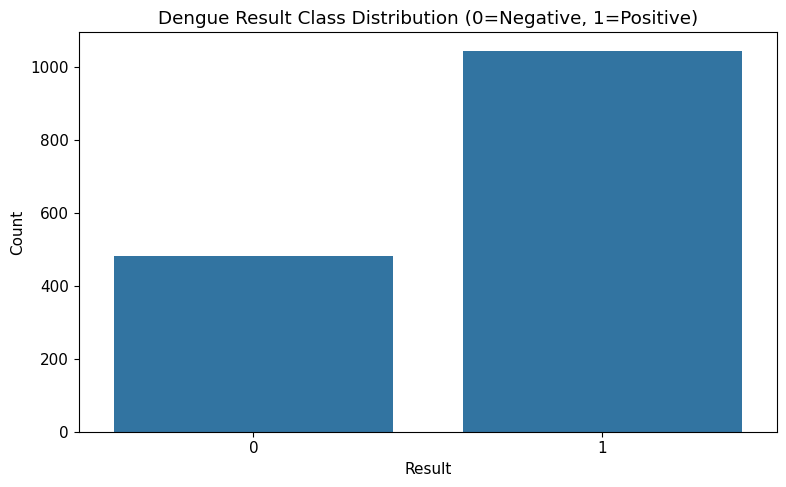


Note: The target classes are imbalanced.


In [57]:
counts = df['result_bin'].value_counts()
percentages = df['result_bin'].value_counts(normalize=True) * 100

print("Class Counts:\n", counts)
print("\nClass Percentages (%):\n", percentages)

plt.figure()
sns.countplot(x='result_bin', data=df)
plt.title("Dengue Result Class Distribution (0=Negative, 1=Positive)")
plt.xlabel("Result")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

if percentages.min() < 40:
    print("\nNote: The target classes are imbalanced.")
else:
    print("\nNote: The target classes are relatively balanced.")

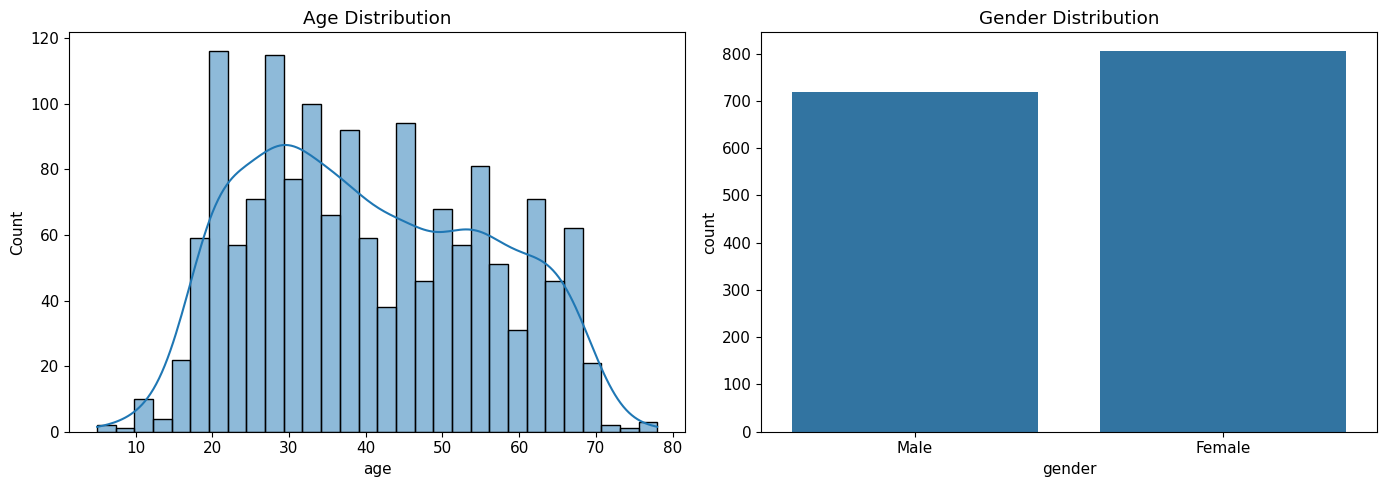

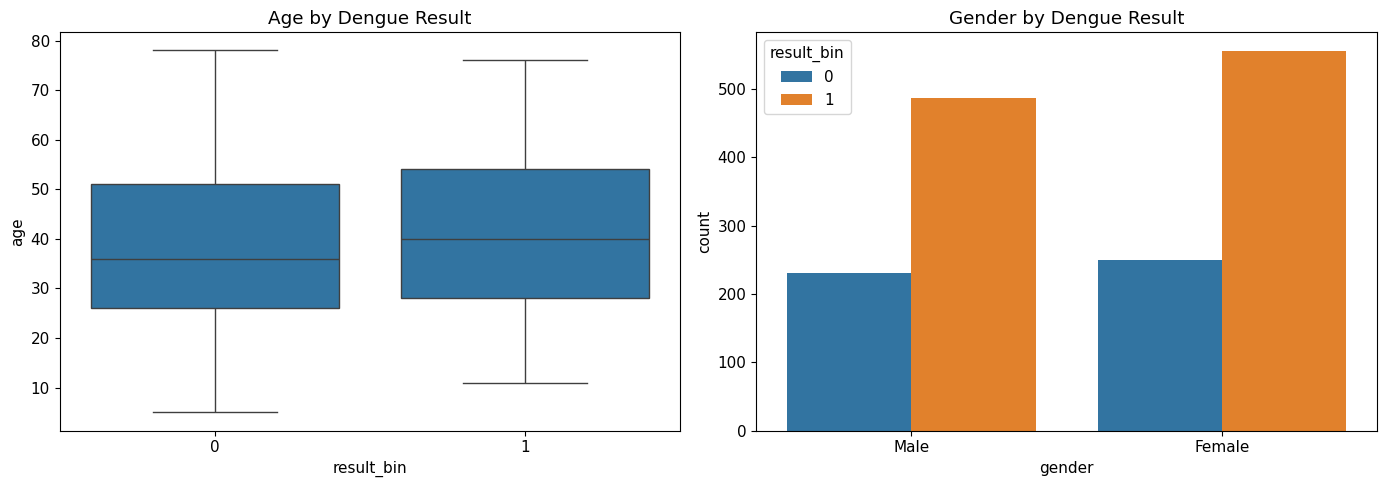

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['age'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")
sns.countplot(x='gender', data=df, ax=axes[1])
axes[1].set_title("Gender Distribution")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='result_bin', y='age', data=df, ax=axes[0])
axes[0].set_title("Age by Dengue Result")
sns.countplot(x='gender', hue='result_bin', data=df, ax=axes[1])
axes[1].set_title("Gender by Dengue Result")
plt.tight_layout()
plt.show()

In [59]:
n_before = df.shape[0]
n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
n_after = df.shape[0]

print("Rows Before:", n_before)
print("Duplicates Removed:", n_dupes)
print("Rows After:", n_after)

Rows Before: 1523
Duplicates Removed: 12
Rows After: 1511


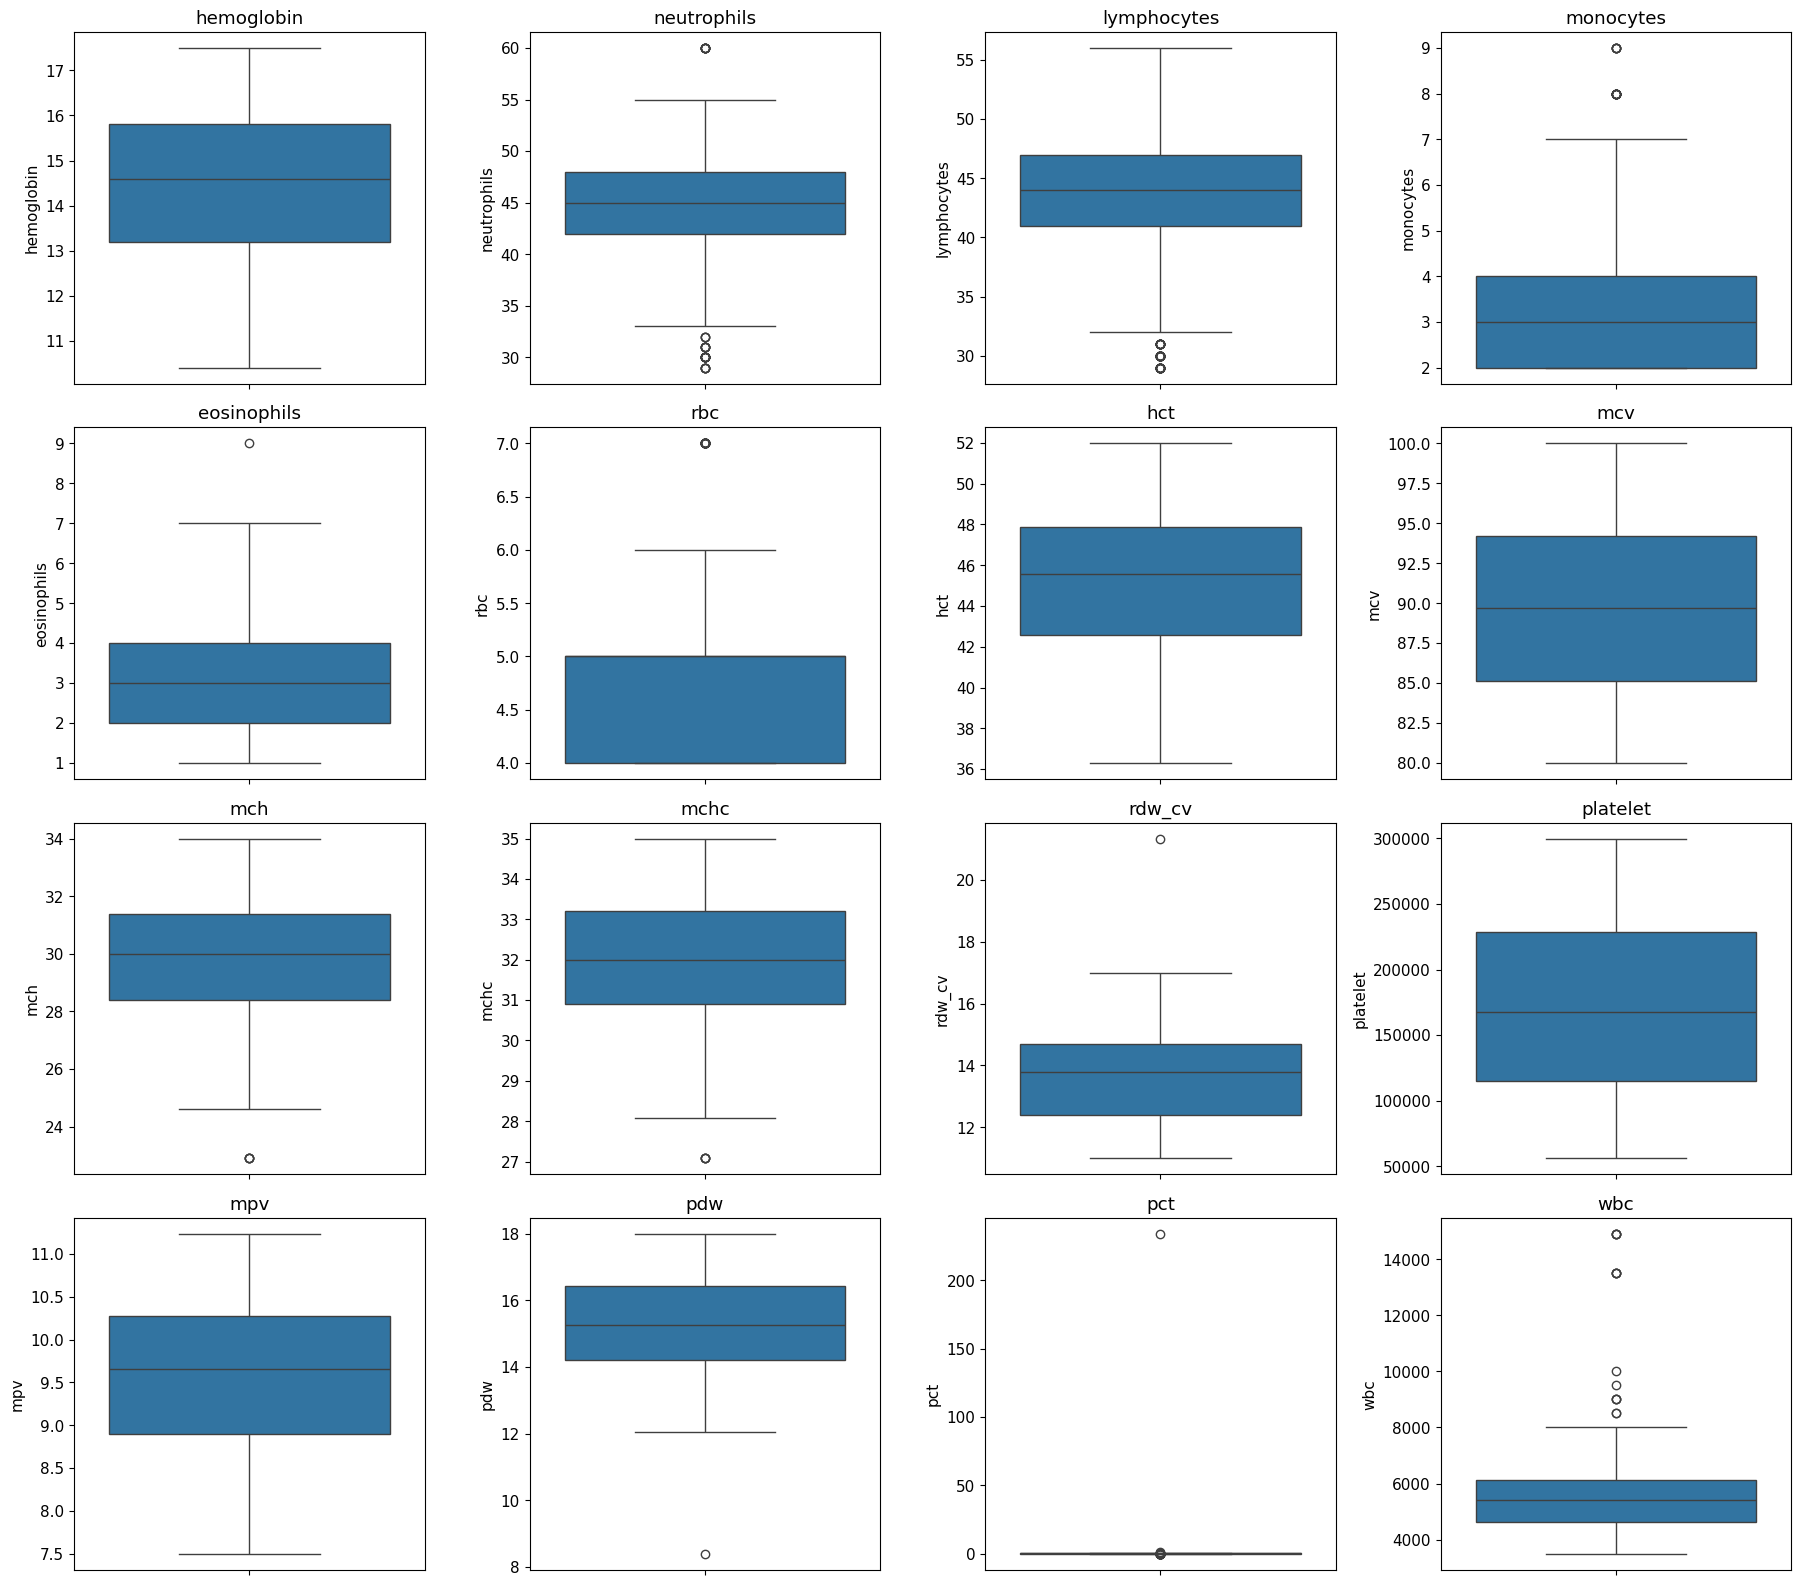

IQR-based outlier counts (reporting only, no removal performed):
hemoglobin: 0 potential outliers (kept - may be clinically meaningful)
neutrophils: 35 potential outliers (kept - may be clinically meaningful)
lymphocytes: 67 potential outliers (kept - may be clinically meaningful)
monocytes: 17 potential outliers (kept - may be clinically meaningful)
eosinophils: 1 potential outliers (kept - may be clinically meaningful)
rbc: 33 potential outliers (kept - may be clinically meaningful)
hct: 0 potential outliers (kept - may be clinically meaningful)
mcv: 0 potential outliers (kept - may be clinically meaningful)
mch: 4 potential outliers (kept - may be clinically meaningful)
mchc: 4 potential outliers (kept - may be clinically meaningful)
rdw_cv: 1 potential outliers (kept - may be clinically meaningful)
platelet: 0 potential outliers (kept - may be clinically meaningful)
mpv: 0 potential outliers (kept - may be clinically meaningful)
pdw: 1 potential outliers (kept - may be clinically m

In [60]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(CBC_FEATURES):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

print("IQR-based outlier counts (reporting only, no removal performed):")
for col in CBC_FEATURES:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_out} potential outliers (kept - may be clinically meaningful)")

In [61]:
y_all = df['result_bin'].copy()

df_train, df_test, y_train, y_test = train_test_split(
    df.copy(), y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)

df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Train Shape:", df_train.shape)
print("Test Shape:", df_test.shape)
print("\nTrain Class Distribution:\n", y_train.value_counts(normalize=True))
print("\nTest Class Distribution:\n", y_test.value_counts(normalize=True))

Train Shape: (1208, 21)
Test Shape: (303, 21)

Train Class Distribution:
 result_bin
1    0.684603
0    0.315397
Name: proportion, dtype: float64

Test Class Distribution:
 result_bin
1    0.686469
0    0.313531
Name: proportion, dtype: float64


In [62]:
num_cols = ['age'] + CBC_FEATURES
cat_cols = ['gender_enc']

imputer_num = SimpleImputer(strategy='median')
imputer_cat = SimpleImputer(strategy='most_frequent')

imputer_num.fit(df_train[num_cols])
imputer_cat.fit(df_train[cat_cols])

df_train[num_cols] = imputer_num.transform(df_train[num_cols])
df_test[num_cols] = imputer_num.transform(df_test[num_cols])

df_train[cat_cols] = imputer_cat.transform(df_train[cat_cols])
df_test[cat_cols] = imputer_cat.transform(df_test[cat_cols])

print("Missing values in train after imputation:", df_train[num_cols + cat_cols].isnull().sum().sum())
print("Missing values in test after imputation:", df_test[num_cols + cat_cols].isnull().sum().sum())

Missing values in train after imputation: 0
Missing values in test after imputation: 0


In [63]:
X_raw_train = df_train[CBC_FEATURES].copy()
X_raw_test = df_test[CBC_FEATURES].copy()

X_raw_demo_train = df_train[CBC_FEATURES + ['age', 'gender_enc']].copy()
X_raw_demo_test = df_test[CBC_FEATURES + ['age', 'gender_enc']].copy()

print("CBC-only feature set shape:", X_raw_train.shape)
print("CBC + Demographic feature set shape:", X_raw_demo_train.shape)

rf_check = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
cv_check = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

auc_cbc = cross_val_score(rf_check, X_raw_train, y_train, cv=cv_check, scoring='roc_auc').mean()
auc_cbc_demo = cross_val_score(rf_check, X_raw_demo_train, y_train, cv=cv_check, scoring='roc_auc').mean()

print(f"\nCV ROC-AUC (CBC-only): {auc_cbc:.4f}")
print(f"CV ROC-AUC (CBC + Demographic): {auc_cbc_demo:.4f}")
print("\nThe main D-CHSS methodology focuses on CBC-only hematological features.")

CBC-only feature set shape: (1208, 16)
CBC + Demographic feature set shape: (1208, 18)

CV ROC-AUC (CBC-only): 0.6619
CV ROC-AUC (CBC + Demographic): 0.6622

The main D-CHSS methodology focuses on CBC-only hematological features.


## Clinical Reference Ranges for CBC Deviation Calculation
Standard adult reference ranges (sex-specific for Hemoglobin, RBC, HCT) are used to compute
normalized deviation — not to replace raw values.

In [64]:
REFERENCE_RANGES = {
    'hemoglobin': {'male': (13.0, 17.0), 'female': (12.0, 15.5), 'default': (12.0, 17.0)},
    'rbc':        {'male': (4.5, 5.5),   'female': (4.0, 5.0),   'default': (4.0, 5.5)},
    'hct':        {'male': (40.0, 50.0), 'female': (36.0, 44.0), 'default': (36.0, 50.0)},
    'neutrophils': (40.0, 70.0),
    'lymphocytes': (20.0, 40.0),
    'monocytes':   (2.0, 8.0),
    'eosinophils': (1.0, 6.0),
    'mcv':         (80.0, 100.0),
    'mch':         (27.0, 33.0),
    'mchc':        (32.0, 36.0),
    'rdw_cv':      (11.5, 14.5),
    'platelet':    (150000.0, 450000.0),
    'mpv':         (7.5, 11.5),
    'pdw':         (9.0, 17.0),
    'pct':         (0.17, 0.35),
    'wbc':         (4000.0, 11000.0)
}

SEX_SPECIFIC_PARAMS = ['hemoglobin', 'rbc', 'hct']

def get_range(param, gender_val):
    r = REFERENCE_RANGES[param]
    if isinstance(r, dict):
        if gender_val == 1:
            return r['male']
        elif gender_val == 0:
            return r['female']
        else:
            return r['default']
    return r

print("Reference ranges defined for", len(REFERENCE_RANGES), "CBC parameters.")

Reference ranges defined for 16 CBC parameters.


In [65]:
MAX_DEV = 3.0  # cap deviation at 300% so a single extreme/erroneous value cannot dominate

def compute_deviation(data, param):
    genders = data['gender_enc'].values
    L_arr = np.zeros(len(data))
    U_arr = np.zeros(len(data))
    for i, g in enumerate(genders):
        L, U = get_range(param, g)
        L_arr[i], U_arr[i] = L, U
    x = data[param].values.astype(float)
    dev = np.zeros(len(x))
    low_mask = x < L_arr
    high_mask = x > U_arr
    dev[low_mask] = -(L_arr[low_mask] - x[low_mask]) / L_arr[low_mask]
    dev[high_mask] = (x[high_mask] - U_arr[high_mask]) / U_arr[high_mask]
    dev = np.clip(dev, -MAX_DEV, MAX_DEV)
    return dev

def add_deviation_features(data):
    data = data.copy()
    for param in CBC_FEATURES:
        data[f'{param}_dev'] = compute_deviation(data, param)
    return data

df_train = add_deviation_features(df_train)
df_test = add_deviation_features(df_test)

DEV_FEATURES = [f'{p}_dev' for p in CBC_FEATURES]
X_dev_train = df_train[DEV_FEATURES].copy()
X_dev_test = df_test[DEV_FEATURES].copy()

print("Deviation features created (capped at +/-", MAX_DEV, "):")
df_train[DEV_FEATURES].describe().T[['min', 'max', 'mean']]

Deviation features created (capped at +/- 3.0 ):


,min,max,mean
hemoglobin_dev,-0.200000,0.129032,0.002606
neutrophils_dev,-0.275000,0.000000,-0.009002
lymphocytes_dev,0.000000,0.400000,0.109002
monocytes_dev,0.000000,0.125000,0.000517
eosinophils_dev,0.000000,0.500000,0.001380
rbc_dev,-0.111111,0.400000,0.002866
hct_dev,-0.092500,0.180909,0.024283
mcv_dev,0.000000,0.000000,0.000000
mch_dev,-0.151852,0.030303,-0.001296
mchc_dev,-0.153750,0.000000,-0.019419


In [66]:
def compute_state(data, param):
    states = []
    for val, g in zip(data[param], data['gender_enc']):
        L, U = get_range(param, g)
        if val < L:
            states.append('LOW')
        elif val > U:
            states.append('HIGH')
        else:
            states.append('NORMAL')
    return states

def add_state_features(data):
    data = data.copy()
    for param in CBC_FEATURES:
        data[f'{param}_state'] = compute_state(data, param)
        data[f'{param}_state_num'] = data[f'{param}_state'].map({'LOW': -1, 'NORMAL': 0, 'HIGH': 1})
    return data

df_train = add_state_features(df_train)
df_test = add_state_features(df_test)

STATE_FEATURES = [f'{p}_state' for p in CBC_FEATURES]
df_train[['platelet', 'platelet_state', 'wbc', 'wbc_state', 'hct', 'hct_state']].head()

,platelet,platelet_state,wbc,wbc_state,hct,hct_state
0,189000.0,NORMAL,8000.0,NORMAL,49.00,NORMAL
1,194000.0,NORMAL,7500.0,NORMAL,49.93,HIGH
2,262639.0,NORMAL,6035.0,NORMAL,49.79,HIGH
3,195106.0,NORMAL,5596.0,NORMAL,46.83,NORMAL
4,110609.0,LOW,6888.0,NORMAL,41.43,NORMAL


In [67]:
THROMBO_PARAMS = ['platelet', 'mpv', 'pdw', 'pct']
LEUKO_PARAMS = ['wbc', 'neutrophils', 'lymphocytes', 'monocytes', 'eosinophils']
HEMO_PARAMS = ['hct', 'hemoglobin', 'rbc']

def compute_component_raw(data, params):
    dev_cols = [f'{p}_dev' for p in params]
    return data[dev_cols].abs().mean(axis=1)

df_train['TS_raw'] = compute_component_raw(df_train, THROMBO_PARAMS)
df_test['TS_raw'] = compute_component_raw(df_test, THROMBO_PARAMS)

df_train['LS_raw'] = compute_component_raw(df_train, LEUKO_PARAMS)
df_test['LS_raw'] = compute_component_raw(df_test, LEUKO_PARAMS)

df_train['HS_raw'] = compute_component_raw(df_train, HEMO_PARAMS)
df_test['HS_raw'] = compute_component_raw(df_test, HEMO_PARAMS)

print("Component raw score stats:")
df_train[['TS_raw', 'LS_raw', 'HS_raw']].describe()

Component raw score stats:


,TS_raw,LS_raw,HS_raw
count,1208.000000,1208.000000,1208.000000
mean,0.089695,0.024428,0.029452
std,0.088594,0.024405,0.031436
min,0.000000,0.000000,0.000000
25%,0.016176,0.005000,0.000576
50%,0.073529,0.020000,0.025641
75%,0.129719,0.040000,0.041617
max,0.870000,0.234242,0.207820


## Improved Feature Engineering: Clinically Established Hematological Ratios

NLR (Neutrophil-to-Lymphocyte Ratio), PLR (Platelet-to-Lymphocyte Ratio), and LMR
(Lymphocyte-to-Monocyte Ratio) are widely reported inflammatory/infection markers in the
dengue and general infectious-disease literature. PDW/MPV and RDW/Platelet ratios capture
combined platelet-morphology and hemoconcentration-platelet interaction signals.

All ratios are computed strictly from CBC columns already present in the dataset — no new
clinical measurements are introduced, and no information from the target variable is used.

In [68]:
def add_ratio_features(data):
    data = data.copy()
    eps = 1e-6  # avoid division by zero
    data['nlr'] = data['neutrophils'] / (data['lymphocytes'] + eps)
    data['plr'] = data['platelet'] / (data['lymphocytes'] + eps)
    data['lmr'] = data['lymphocytes'] / (data['monocytes'] + eps)
    data['pdw_mpv_ratio'] = data['pdw'] / (data['mpv'] + eps)
    data['rdw_platelet_ratio'] = data['rdw_cv'] / (data['platelet'] + eps) * 1000  # scaled for readability
    return data

df_train = add_ratio_features(df_train)
df_test = add_ratio_features(df_test)

RATIO_FEATURES = ['nlr', 'plr', 'lmr', 'pdw_mpv_ratio', 'rdw_platelet_ratio']

print("Ratio feature stats (train):")
df_train[RATIO_FEATURES].describe()

Ratio feature stats (train):


,nlr,plr,lmr,pdw_mpv_ratio,rdw_platelet_ratio
count,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000
mean,1.043415,3998.731647,14.853514,1.609443,0.091861
std,0.202608,1443.519925,5.004598,0.205351,0.039747
min,0.600000,1359.999973,3.777777,0.813875,0.036769
25%,0.931818,2851.722159,10.999997,1.460036,0.058592
50%,1.000000,3791.321141,13.999995,1.589520,0.083021
75%,1.116279,5116.309835,19.124990,1.733623,0.117801
max,2.068965,9266.666358,24.999988,2.209617,0.226176


In [69]:
component_scaler = StandardScaler()
component_scaler.fit(df_train[['TS_raw', 'LS_raw', 'HS_raw']])

train_std = component_scaler.transform(df_train[['TS_raw', 'LS_raw', 'HS_raw']])
test_std = component_scaler.transform(df_test[['TS_raw', 'LS_raw', 'HS_raw']])

df_train['TS_std'], df_train['LS_std'], df_train['HS_std'] = train_std[:, 0], train_std[:, 1], train_std[:, 2]
df_test['TS_std'], df_test['LS_std'], df_test['HS_std'] = test_std[:, 0], test_std[:, 1], test_std[:, 2]

weight_logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
weight_logreg.fit(df_train[['TS_std', 'LS_std', 'HS_std']], y_train)

coefs = weight_logreg.coef_[0]
abs_coefs = np.abs(coefs)
weights = abs_coefs / abs_coefs.sum()
w_ts, w_ls, w_hs = weights[0], weights[1], weights[2]

print("Learned coefficients:", coefs)
print(f"\nLearned D-CHSS weights (training data only):")
print(f"  w_ts (Thrombocytopenia): {w_ts:.4f}")
print(f"  w_ls (Leukocyte Response): {w_ls:.4f}")
print(f"  w_hs (Hemoconcentration): {w_hs:.4f}")

df_train['DCHSS'] = w_ts * df_train['TS_std'] + w_ls * df_train['LS_std'] + w_hs * df_train['HS_std']
df_test['DCHSS'] = w_ts * df_test['TS_std'] + w_ls * df_test['LS_std'] + w_hs * df_test['HS_std']

DCHSS_COMPONENT_FEATURES = ['TS_std', 'LS_std', 'HS_std', 'DCHSS']
df_train['DCHSS'].describe()

Learned coefficients: [-0.12830325 -0.5048285  -0.25422906]

Learned D-CHSS weights (training data only):
  w_ts (Thrombocytopenia): 0.1446
  w_ls (Leukocyte Response): 0.5689
  w_hs (Hemoconcentration): 0.2865


count    1.208000e+03
mean     5.146729e-18
std      7.012574e-01
min     -9.846448e-01
25%     -4.416779e-01
50%     -1.414772e-01
75%      2.650660e-01
max      5.436600e+00
Name: DCHSS, dtype: float64

## Leakage-Safe Pipeline

1. Train/test split done first (Cell 13).
2. Imputation fit only on train (Cell 14).
3. Reference ranges are fixed clinical constants — safe to apply to both sets.
4. Ratio features are deterministic transforms of raw values — no fitting involved, safe for both sets.
5. D-CHSS component scaler and logistic regression weights fit only on train (Cell 23).
6. Hyperparameter tuning uses only training-set cross-validation (no test set).
7. The classification decision threshold is learned from out-of-fold training predictions only.
8. Model selection among candidates (single model vs ensembles) is based on training CV only.
9. Test set is used only once, at final evaluation.
10. Cross-validation stability analysis re-fits scaler/weights inside each fold (no leakage).

In [70]:
scaler_raw = StandardScaler()
scaler_raw.fit(X_raw_train)

X_raw_train_scaled = pd.DataFrame(scaler_raw.transform(X_raw_train), columns=CBC_FEATURES)
X_raw_test_scaled = pd.DataFrame(scaler_raw.transform(X_raw_test), columns=CBC_FEATURES)

print("Scaled CBC features ready for Logistic Regression / SVM.")

Scaled CBC features ready for Logistic Regression / SVM.


In [71]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'XGBoost': xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

for name, model in baseline_models.items():
    X_use = X_raw_train_scaled if name in ['Logistic Regression', 'SVM'] else X_raw_train
    scores = cross_val_score(model, X_use, y_train, cv=cv_strategy, scoring='roc_auc')
    print(f"{name}: CV ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

Logistic Regression: CV ROC-AUC = 0.6459 +/- 0.0341
Decision Tree: CV ROC-AUC = 0.5973 +/- 0.0409
Random Forest: CV ROC-AUC = 0.6556 +/- 0.0511
SVM: CV ROC-AUC = 0.6580 +/- 0.0428
XGBoost: CV ROC-AUC = 0.6314 +/- 0.0500


In [72]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2'], 'solver': ['lbfgs'],
                             'class_weight': [None, 'balanced']},
    'Decision Tree': {'max_depth': [3, 5, 7, None], 'min_samples_split': [2, 5, 10],
                       'min_samples_leaf': [1, 2, 4], 'class_weight': [None, 'balanced']},
    'Random Forest': {'n_estimators': [100, 200, 300], 'max_depth': [5, 10, None],
                       'min_samples_split': [2, 5], 'max_features': ['sqrt', 'log2'],
                       'class_weight': [None, 'balanced']},
    'SVM': {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto'], 'kernel': ['rbf'],
            'class_weight': [None, 'balanced']},
    'XGBoost': {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.01, 0.1],
                'subsample': [0.8, 1.0], 'colsample_bytree': [0.8, 1.0]}
}

base_estimators = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'XGBoost': xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

best_models = {}
best_params = {}

for name, estimator in base_estimators.items():
    X_use = X_raw_train_scaled if name in ['Logistic Regression', 'SVM'] else X_raw_train
    grid = GridSearchCV(estimator, param_grids[name], cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_use, y_train)
    best_models[name] = grid.best_estimator_
    best_params[name] = grid.best_params_
    print(f"{name}: Best CV ROC-AUC = {grid.best_score_:.4f} | Params: {grid.best_params_}")

Logistic Regression: Best CV ROC-AUC = 0.6470 | Params: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
Decision Tree: Best CV ROC-AUC = 0.6634 | Params: {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 10}
Random Forest: Best CV ROC-AUC = 0.6923 | Params: {'class_weight': None, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 300}
SVM: Best CV ROC-AUC = 0.6736 | Params: {'C': 0.1, 'class_weight': None, 'gamma': 'scale', 'kernel': 'rbf'}
XGBoost: Best CV ROC-AUC = 0.7028 | Params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


In [74]:
def calculate_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': specificity,
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob),
        'MCC': matthews_corrcoef(y_true, y_pred)
    }

baseline_test_metrics = {}
for name, model in best_models.items():
    X_use_test = X_raw_test_scaled if name in ['Logistic Regression', 'SVM'] else X_raw_test
    y_pred = model.predict(X_use_test)
    y_prob = model.predict_proba(X_use_test)[:, 1]
    baseline_test_metrics[name] = calculate_metrics(y_test, y_pred, y_prob)

baseline_results_df = pd.DataFrame(baseline_test_metrics).T
baseline_results_df

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Logistic Regression,0.617162,0.732323,0.697115,0.442105,0.714286,0.621609,0.747756,0.135728
Decision Tree,0.749175,0.761905,0.923077,0.368421,0.834783,0.633376,0.748849,0.361446
Random Forest,0.759076,0.752809,0.966346,0.305263,0.846316,0.662500,0.767944,0.389432
SVM,0.719472,0.717314,0.975962,0.157895,0.826884,0.658426,0.781649,0.250106
XGBoost,0.759076,0.747253,0.980769,0.273684,0.848233,0.658401,0.774668,0.395239


In [75]:
X_dchss_train = df_train[DCHSS_COMPONENT_FEATURES].copy()
X_dchss_test = df_test[DCHSS_COMPONENT_FEATURES].copy()

# The proposed final feature set: Raw CBC + Deviation + D-CHSS components + Ratios
FULL_FEATURES = CBC_FEATURES + DEV_FEATURES + DCHSS_COMPONENT_FEATURES + RATIO_FEATURES
X_full_train = df_train[FULL_FEATURES].copy()
X_full_test = df_test[FULL_FEATURES].copy()

print("Feature set sizes:")
print(f"  Raw CBC only:            {X_raw_train.shape[1]}")
print(f"  Deviation only:          {X_dev_train.shape[1]}")
print(f"  D-CHSS components only:  {X_dchss_train.shape[1]}")
print(f"  Full (proposed):         {X_full_train.shape[1]}")

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_value = neg_count / pos_count
print(f"\nTrain class counts -> Negative: {neg_count}, Positive: {pos_count}")
print(f"scale_pos_weight: {scale_pos_weight_value:.4f}")

Feature set sizes:
  Raw CBC only:            16
  Deviation only:          16
  D-CHSS components only:  4
  Full (proposed):         41

Train class counts -> Negative: 381, Positive: 827
scale_pos_weight: 0.4607


## Wider, Imbalance-Aware Hyperparameter Search for the Proposed Full Feature Set

RandomizedSearchCV explores a broader hyperparameter space than the baseline grid search,
including regularization (`min_child_weight`, `gamma`) and `scale_pos_weight` to explicitly
address class imbalance. The same tuned hyperparameters are reused across all ablation models
(A/B/C/D) so that observed performance differences reflect the FEATURE SET only.

In [76]:
param_dist = {
    'n_estimators': [100, 150, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1, 0.15],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.3],
    'scale_pos_weight': [1, scale_pos_weight_value]
}

xgb_random_search = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
    param_distributions=param_dist,
    n_iter=80,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=RANDOM_STATE
)

xgb_random_search.fit(X_full_train, y_train)

dchss_best_params = xgb_random_search.best_params_
print(f"Best CV ROC-AUC (Full Feature Set): {xgb_random_search.best_score_:.4f}")
print(f"Best Params: {dchss_best_params}")

Best CV ROC-AUC (Full Feature Set): 0.6963
Best Params: {'subsample': 0.6, 'scale_pos_weight': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.8}


In [77]:
# Model A: Raw CBC + XGBoost
model_A = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_A.fit(X_raw_train, y_train)
y_prob_A = model_A.predict_proba(X_raw_test)[:, 1]
y_pred_A = (y_prob_A >= 0.5).astype(int)
metrics_A = calculate_metrics(y_test, y_pred_A, y_prob_A)

print("Model A (Raw CBC + XGBoost):")
for k, v in metrics_A.items():
    print(f"  {k}: {v:.4f}")

Model A (Raw CBC + XGBoost):
  Accuracy: 0.7657
  Precision: 0.7528
  Recall: 0.9808
  Specificity: 0.2947
  F1: 0.8518
  ROC-AUC: 0.6531
  PR-AUC: 0.7623
  MCC: 0.4159


In [78]:
# Model B: Deviation Features + XGBoost
model_B = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_B.fit(X_dev_train, y_train)
y_prob_B = model_B.predict_proba(X_dev_test)[:, 1]
y_pred_B = (y_prob_B >= 0.5).astype(int)
metrics_B = calculate_metrics(y_test, y_pred_B, y_prob_B)

print("Model B (Deviation Features + XGBoost):")
for k, v in metrics_B.items():
    print(f"  {k}: {v:.4f}")

Model B (Deviation Features + XGBoost):
  Accuracy: 0.7591
  Precision: 0.7491
  Recall: 0.9760
  Specificity: 0.2842
  F1: 0.8476
  ROC-AUC: 0.6326
  PR-AUC: 0.7528
  MCC: 0.3927


In [79]:
# Model C: D-CHSS Components + XGBoost
model_C = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_C.fit(X_dchss_train, y_train)
y_prob_C = model_C.predict_proba(X_dchss_test)[:, 1]
y_pred_C = (y_prob_C >= 0.5).astype(int)
metrics_C = calculate_metrics(y_test, y_pred_C, y_prob_C)

print("Model C (D-CHSS Components + XGBoost):")
for k, v in metrics_C.items():
    print(f"  {k}: {v:.4f}")

Model C (D-CHSS Components + XGBoost):
  Accuracy: 0.7426
  Precision: 0.7372
  Recall: 0.9712
  Specificity: 0.2421
  F1: 0.8382
  ROC-AUC: 0.6041
  PR-AUC: 0.7219
  MCC: 0.3363


In [80]:
# Model D: Raw + Deviation + D-CHSS + Ratios + XGBoost (default threshold, before ensemble/threshold optimization)
model_D = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
model_D.fit(X_full_train, y_train)
y_prob_D_xgb = model_D.predict_proba(X_full_test)[:, 1]
y_pred_D_xgb_default = (y_prob_D_xgb >= 0.5).astype(int)
metrics_D_xgb_default = calculate_metrics(y_test, y_pred_D_xgb_default, y_prob_D_xgb)

print("Model D (Full Feature XGBoost) - Default Threshold 0.5:")
for k, v in metrics_D_xgb_default.items():
    print(f"  {k}: {v:.4f}")

Model D (Full Feature XGBoost) - Default Threshold 0.5:
  Accuracy: 0.7624
  Precision: 0.7500
  Recall: 0.9808
  Specificity: 0.2842
  F1: 0.8500
  ROC-AUC: 0.6847
  PR-AUC: 0.7997
  MCC: 0.4056


## Ensemble Models: Voting and Stacking

Combining diverse base learners (Logistic Regression, Random Forest, XGBoost) via soft
voting or a stacked meta-learner typically improves generalization and stability compared
to any single model, by leveraging complementary decision boundaries. The best-performing
candidate (single XGBoost vs Voting vs Stacking), selected via training-only cross-validation,
becomes the final proposed D-CHSS-XGBoost model.

In [81]:
lr_for_ensemble = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced')
rf_for_ensemble = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE,
                                          class_weight='balanced')
xgb_for_ensemble = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')

voting_clf = VotingClassifier(
    estimators=[('lr', lr_for_ensemble), ('rf', rf_for_ensemble), ('xgb', xgb_for_ensemble)],
    voting='soft'
)

stacking_clf = StackingClassifier(
    estimators=[('lr', lr_for_ensemble), ('rf', rf_for_ensemble), ('xgb', xgb_for_ensemble)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv_strategy,
    stack_method='predict_proba'
)

xgb_full_model = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')

xgb_full_cv_auc = cross_val_score(xgb_full_model, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')
voting_cv_auc = cross_val_score(voting_clf, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')
stacking_cv_auc = cross_val_score(stacking_clf, X_full_train, y_train, cv=cv_strategy, scoring='roc_auc')

print("Candidate Model Comparison (Training CV ROC-AUC, Full Feature Set):")
print(f"  XGBoost (single):    {xgb_full_cv_auc.mean():.4f} +/- {xgb_full_cv_auc.std():.4f}")
print(f"  Voting Ensemble:     {voting_cv_auc.mean():.4f} +/- {voting_cv_auc.std():.4f}")
print(f"  Stacking Ensemble:   {stacking_cv_auc.mean():.4f} +/- {stacking_cv_auc.std():.4f}")

Candidate Model Comparison (Training CV ROC-AUC, Full Feature Set):
  XGBoost (single):    0.6963 +/- 0.0554
  Voting Ensemble:     0.6868 +/- 0.0464
  Stacking Ensemble:   0.6922 +/- 0.0519


In [82]:
candidate_models = {
    'XGBoost (Full Features)': (xgb_full_model, xgb_full_cv_auc.mean()),
    'Voting Ensemble': (voting_clf, voting_cv_auc.mean()),
    'Stacking Ensemble': (stacking_clf, stacking_cv_auc.mean())
}

best_candidate_name = max(candidate_models, key=lambda k: candidate_models[k][1])
final_dchss_xgb_model = candidate_models[best_candidate_name][0]

print(f"Selected Final Model (based on training CV ROC-AUC only): {best_candidate_name}")

final_dchss_xgb_model.fit(X_full_train, y_train)
print("Final model fitted on full training data.")

Selected Final Model (based on training CV ROC-AUC only): XGBoost (Full Features)
Final model fitted on full training data.


In [83]:
oof_probs = cross_val_predict(
    final_dchss_xgb_model, X_full_train, y_train,
    cv=cv_strategy, method='predict_proba'
)[:, 1]

fpr_tr, tpr_tr, thresh_tr = roc_curve(y_train, oof_probs)
youden_j = tpr_tr - fpr_tr
best_thresh = thresh_tr[np.argmax(youden_j)]

print(f"Optimal classification threshold learned from training CV (Youden's J): {best_thresh:.4f}")

# Apply frozen threshold to the untouched test set (used exactly once)
y_prob_D = final_dchss_xgb_model.predict_proba(X_full_test)[:, 1]
y_pred_D_default = (y_prob_D >= 0.5).astype(int)
y_pred_D_optimal = (y_prob_D >= best_thresh).astype(int)

metrics_D_default = calculate_metrics(y_test, y_pred_D_default, y_prob_D)
metrics_D_optimal = calculate_metrics(y_test, y_pred_D_optimal, y_prob_D)

threshold_comparison = pd.DataFrame({
    'Default Threshold (0.5)': metrics_D_default,
    f'Optimal Threshold ({best_thresh:.3f})': metrics_D_optimal
}).T

print(f"\nFinal Model: {best_candidate_name}")
print("Threshold Comparison on Final Test Set:")
threshold_comparison.round(4)

Optimal classification threshold learned from training CV (Youden's J): 0.6207

Final Model: XGBoost (Full Features)
Threshold Comparison on Final Test Set:


,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Default Threshold (0.5),0.7624,0.7500,0.9808,0.2842,0.8500,0.6847,0.7997,0.4056
Optimal Threshold (0.621),0.7690,0.7674,0.9519,0.3684,0.8498,0.6847,0.7997,0.4179


In [84]:
# Adopt the optimal-threshold version as the final reported D-CHSS-XGBoost model
y_pred_D = y_pred_D_optimal
metrics_D = metrics_D_optimal

print(f"=== FINAL D-CHSS-XGBoost PERFORMANCE ({best_candidate_name}, Optimized Threshold) ===\n")
for k, v in metrics_D.items():
    print(f"{k}: {v:.4f}")

=== FINAL D-CHSS-XGBoost PERFORMANCE (XGBoost (Full Features), Optimized Threshold) ===

Accuracy: 0.7690
Precision: 0.7674
Recall: 0.9519
Specificity: 0.3684
F1: 0.8498
ROC-AUC: 0.6847
PR-AUC: 0.7997
MCC: 0.4179


In [85]:
ablation_df = pd.DataFrame({
    'Raw CBC + XGBoost': metrics_A,
    'Deviation + XGBoost': metrics_B,
    'D-CHSS + XGBoost': metrics_C,
    f'Raw+Deviation+D-CHSS+Ratios ({best_candidate_name}, Optimal Threshold)': metrics_D
}).T

ablation_df.round(4)

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Raw CBC + XGBoost,0.7657,0.7528,0.9808,0.2947,0.8518,0.6531,0.7623,0.4159
Deviation + XGBoost,0.7591,0.7491,0.9760,0.2842,0.8476,0.6326,0.7528,0.3927
D-CHSS + XGBoost,0.7426,0.7372,0.9712,0.2421,0.8382,0.6041,0.7219,0.3363
"Raw+Deviation+D-CHSS+Ratios (XGBoost (Full Features), Optimal Threshold)",0.7690,0.7674,0.9519,0.3684,0.8498,0.6847,0.7997,0.4179


Best Baseline Model: Random Forest


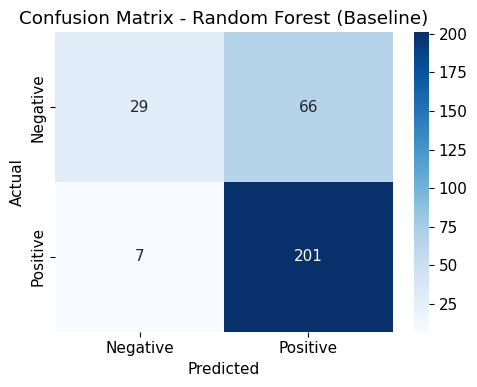

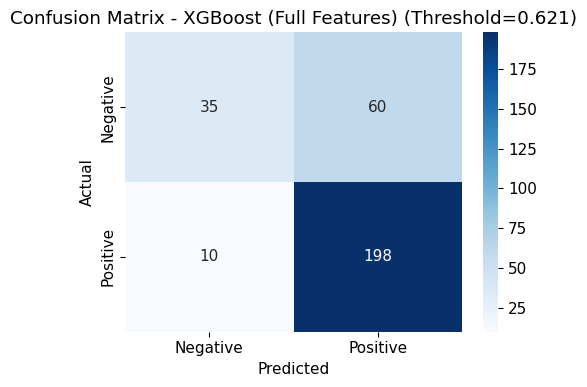

In [86]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

best_baseline_name = baseline_results_df['ROC-AUC'].idxmax()
best_baseline_model = best_models[best_baseline_name]
X_use_best = X_raw_test_scaled if best_baseline_name in ['Logistic Regression', 'SVM'] else X_raw_test
y_pred_best_baseline = best_baseline_model.predict(X_use_best)

print(f"Best Baseline Model: {best_baseline_name}")
plot_confusion(y_test, y_pred_best_baseline, f"Confusion Matrix - {best_baseline_name} (Baseline)")
plot_confusion(y_test, y_pred_D, f"Confusion Matrix - {best_candidate_name} (Threshold={best_thresh:.3f})")

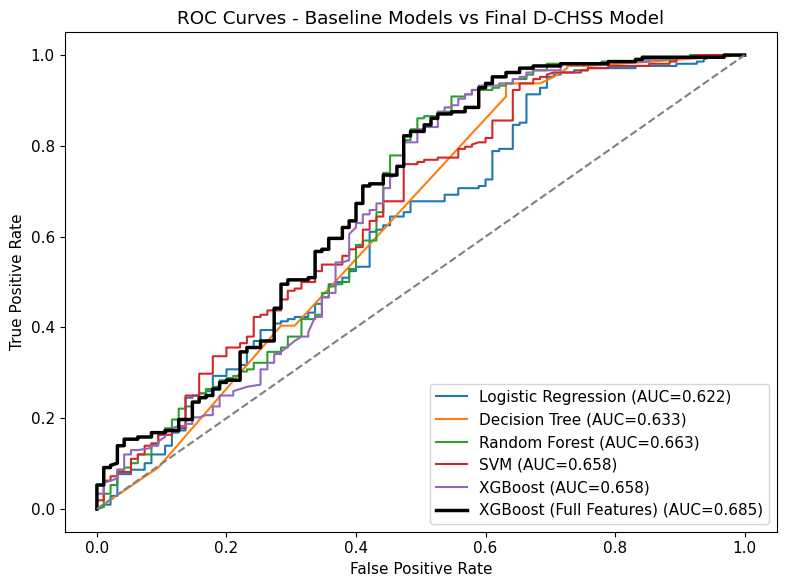

In [87]:
plt.figure(figsize=(8, 6))
for name, model in best_models.items():
    X_use_test = X_raw_test_scaled if name in ['Logistic Regression', 'SVM'] else X_raw_test
    y_prob = model.predict_proba(X_use_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})")

fpr_d, tpr_d, _ = roc_curve(y_test, y_prob_D)
auc_d = roc_auc_score(y_test, y_prob_D)
plt.plot(fpr_d, tpr_d, label=f"{best_candidate_name} (AUC={auc_d:.3f})", linewidth=2.5, color='black')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Baseline Models vs Final D-CHSS Model")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

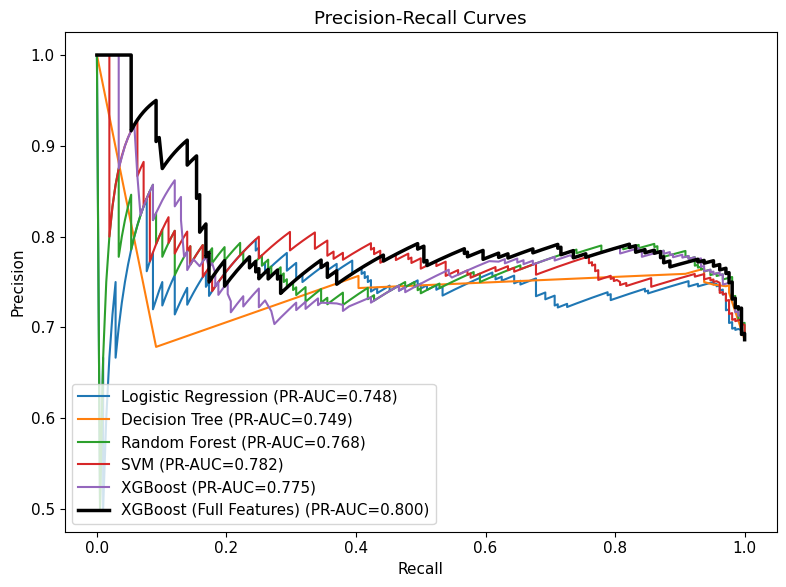

In [88]:
plt.figure(figsize=(8, 6))
for name, model in best_models.items():
    X_use_test = X_raw_test_scaled if name in ['Logistic Regression', 'SVM'] else X_raw_test
    y_prob = model.predict_proba(X_use_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    plt.plot(recall, precision, label=f"{name} (PR-AUC={pr_auc:.3f})")

precision_d, recall_d, _ = precision_recall_curve(y_test, y_prob_D)
pr_auc_d = average_precision_score(y_test, y_prob_D)
plt.plot(recall_d, precision_d, label=f"{best_candidate_name} (PR-AUC={pr_auc_d:.3f})",
         linewidth=2.5, color='black')

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

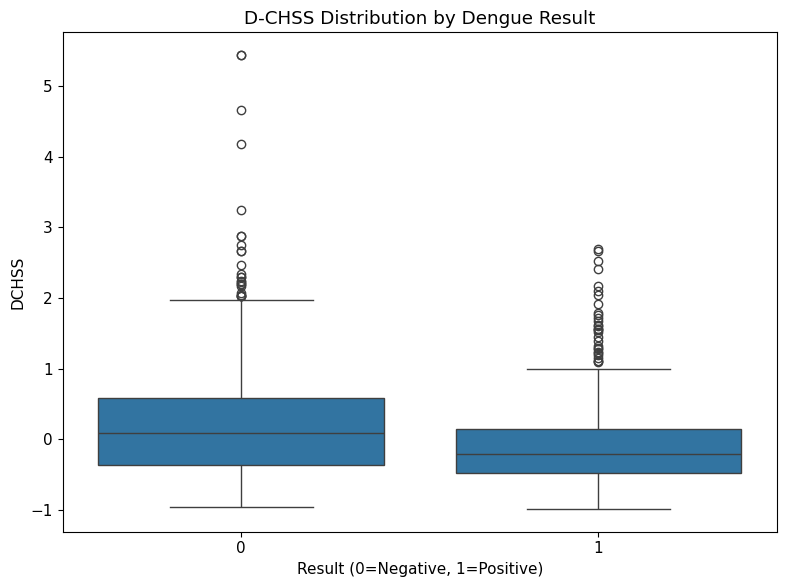

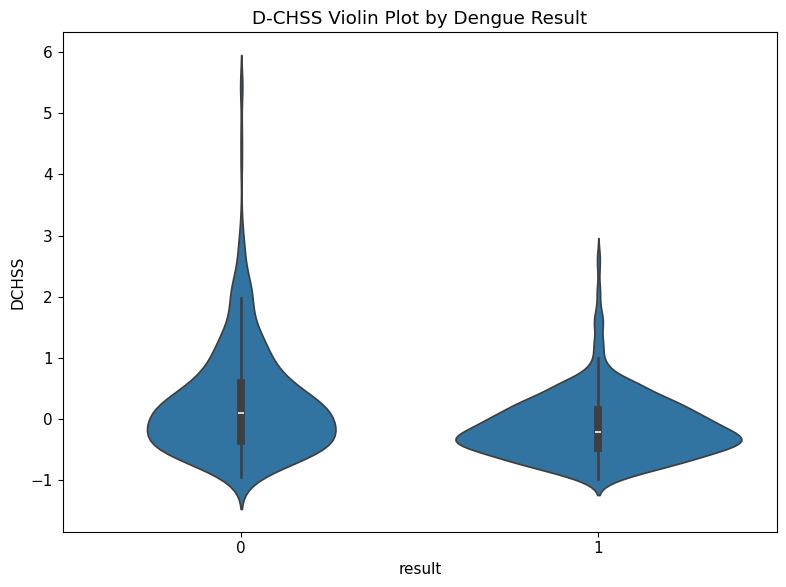

Mann-Whitney U test: U = 179822.50, p-value = 0.000000
Effect size (rank-biserial approx): 0.2700


In [89]:
dchss_all = pd.concat([
    df_train[['DCHSS']].assign(result=y_train.values),
    df_test[['DCHSS']].assign(result=y_test.values)
], axis=0)

plt.figure(figsize=(8, 6))
sns.boxplot(x='result', y='DCHSS', data=dchss_all)
plt.title("D-CHSS Distribution by Dengue Result")
plt.xlabel("Result (0=Negative, 1=Positive)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.violinplot(x='result', y='DCHSS', data=dchss_all)
plt.title("D-CHSS Violin Plot by Dengue Result")
plt.tight_layout()
plt.show()

group_pos = dchss_all[dchss_all['result'] == 1]['DCHSS']
group_neg = dchss_all[dchss_all['result'] == 0]['DCHSS']

u_stat, p_val = mannwhitneyu(group_pos, group_neg, alternative='two-sided')
n1, n2 = len(group_pos), len(group_neg)
effect_size_r = 1 - (2 * u_stat) / (n1 * n2)

print(f"Mann-Whitney U test: U = {u_stat:.2f}, p-value = {p_val:.6f}")
print(f"Effect size (rank-biserial approx): {effect_size_r:.4f}")

Spearman correlation (D-CHSS vs predicted probability): r = -0.5831, p = 0.000000


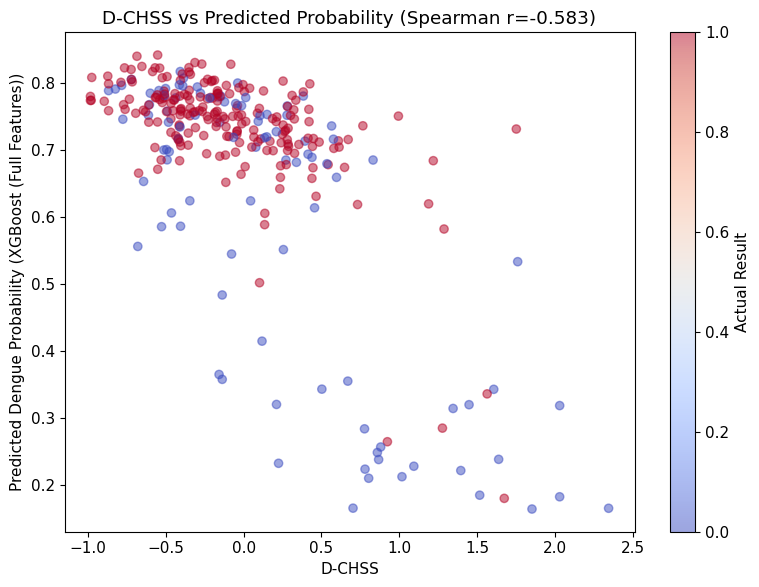

In [90]:
corr, p_corr = spearmanr(df_test['DCHSS'], y_prob_D)
print(f"Spearman correlation (D-CHSS vs predicted probability): r = {corr:.4f}, p = {p_corr:.6f}")

plt.figure(figsize=(8, 6))
sc = plt.scatter(df_test['DCHSS'], y_prob_D, alpha=0.5, c=y_test, cmap='coolwarm')
plt.xlabel("D-CHSS")
plt.ylabel(f"Predicted Dengue Probability ({best_candidate_name})")
plt.title(f"D-CHSS vs Predicted Probability (Spearman r={corr:.3f})")
plt.colorbar(sc, label="Actual Result")
plt.tight_layout()
plt.show()

In [91]:
low_thresh, high_thresh = np.percentile(df_train['DCHSS'], [33.33, 66.67])
print(f"Learned Risk Thresholds (train): Low < {low_thresh:.4f} <= Moderate <= {high_thresh:.4f} < High")

def assign_risk_group(score):
    if score < low_thresh:
        return 'Low'
    elif score <= high_thresh:
        return 'Moderate'
    else:
        return 'High'

df_test['risk_group'] = df_test['DCHSS'].apply(assign_risk_group)

risk_summary = df_test.groupby('risk_group').apply(lambda g: pd.Series({
    'N': len(g),
    'Dengue Positive Rate': g['result_bin'].mean()
})).reindex(['Low', 'Moderate', 'High'])

print("\nHematological Signature Risk Groups (Test Set):")
risk_summary

Learned Risk Thresholds (train): Low < -0.3488 <= Moderate <= 0.1128 < High

Hematological Signature Risk Groups (Test Set):


,N,Dengue Positive Rate
risk_group,,
Low,103.0,0.718447
Moderate,96.0,0.770833
High,104.0,0.576923


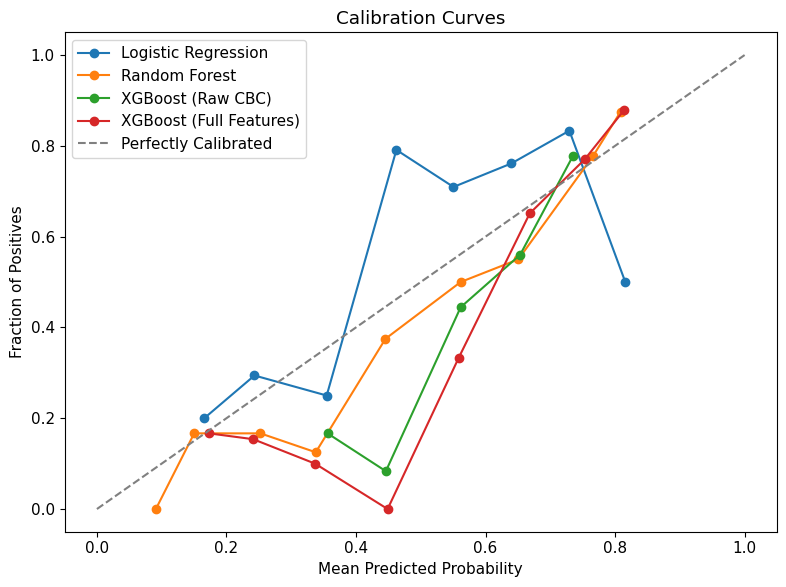

Brier Scores (lower is better):
  Logistic Regression: 0.2264
  Random Forest: 0.1775
  XGBoost (Raw CBC): 0.1851
  XGBoost (Full Features): 0.1779


In [92]:
plt.figure(figsize=(8, 6))

models_for_calibration = {
    'Logistic Regression': (best_models['Logistic Regression'], X_raw_test_scaled),
    'Random Forest': (best_models['Random Forest'], X_raw_test),
    'XGBoost (Raw CBC)': (best_models['XGBoost'], X_raw_test),
    best_candidate_name: (final_dchss_xgb_model, X_full_test)
}

brier_scores = {}
for name, (model, X_use) in models_for_calibration.items():
    y_prob = model.predict_proba(X_use)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10)
    plt.plot(mean_pred, frac_pos, marker='o', label=name)
    brier_scores[name] = brier_score_loss(y_test, y_prob)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves")
plt.legend()
plt.tight_layout()
plt.show()

print("Brier Scores (lower is better):")
for k, v in brier_scores.items():
    print(f"  {k}: {v:.4f}")

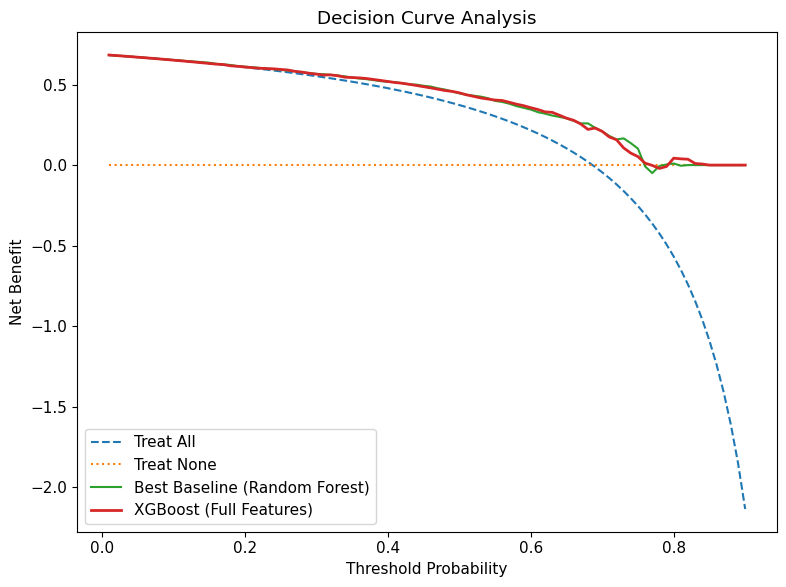

In [93]:
def net_benefit(y_true, y_prob, thresholds):
    n = len(y_true)
    nb = []
    for pt in thresholds:
        pred_pos = (y_prob >= pt).astype(int)
        tp = np.sum((pred_pos == 1) & (y_true == 1))
        fp = np.sum((pred_pos == 1) & (y_true == 0))
        benefit = (tp / n) - (fp / n) * (pt / (1 - pt))
        nb.append(benefit)
    return np.array(nb)

thresholds_dca = np.arange(0.01, 0.91, 0.01)
prevalence = y_test.mean()

nb_all = prevalence - (1 - prevalence) * (thresholds_dca / (1 - thresholds_dca))
nb_none = np.zeros(len(thresholds_dca))

y_prob_best_baseline_cal = best_baseline_model.predict_proba(X_use_best)[:, 1]
nb_baseline = net_benefit(y_test.values, y_prob_best_baseline_cal, thresholds_dca)
nb_dchss = net_benefit(y_test.values, y_prob_D, thresholds_dca)

plt.figure(figsize=(8, 6))
plt.plot(thresholds_dca, nb_all, label='Treat All', linestyle='--')
plt.plot(thresholds_dca, nb_none, label='Treat None', linestyle=':')
plt.plot(thresholds_dca, nb_baseline, label=f'Best Baseline ({best_baseline_name})')
plt.plot(thresholds_dca, nb_dchss, label=best_candidate_name, linewidth=2)
plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")
plt.title("Decision Curve Analysis")
plt.legend()
plt.tight_layout()
plt.show()

## SHAP Explainability

Note: SHAP TreeExplainer requires a tree-based model. If the final selected model is an
ensemble (Voting/Stacking) containing non-tree components, SHAP is computed on the
underlying XGBoost component (`xgb_for_ensemble`, fitted on the full feature set) as a
representative explainer for the tree-based contribution, since it uses identical features.

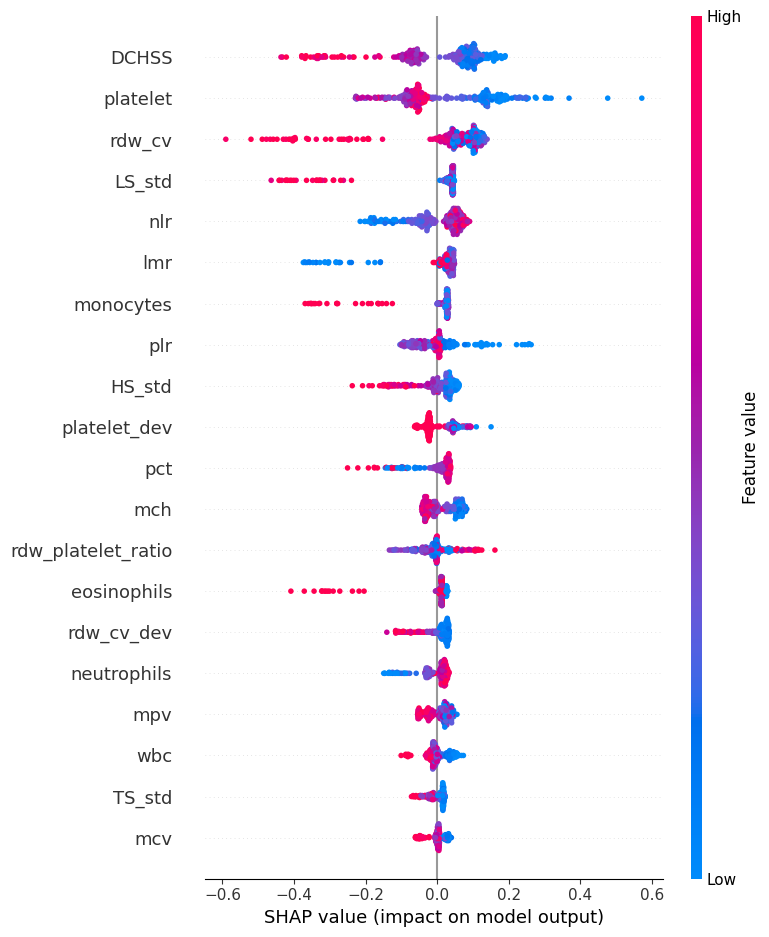

In [94]:
# Use a tree-based model fitted on the same features for SHAP (works regardless of final model type)
shap_model = xgb.XGBClassifier(**dchss_best_params, random_state=RANDOM_STATE, eval_metric='logloss')
shap_model.fit(X_full_train, y_train)

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_full_test)

shap.summary_plot(shap_values, X_full_test, show=True)

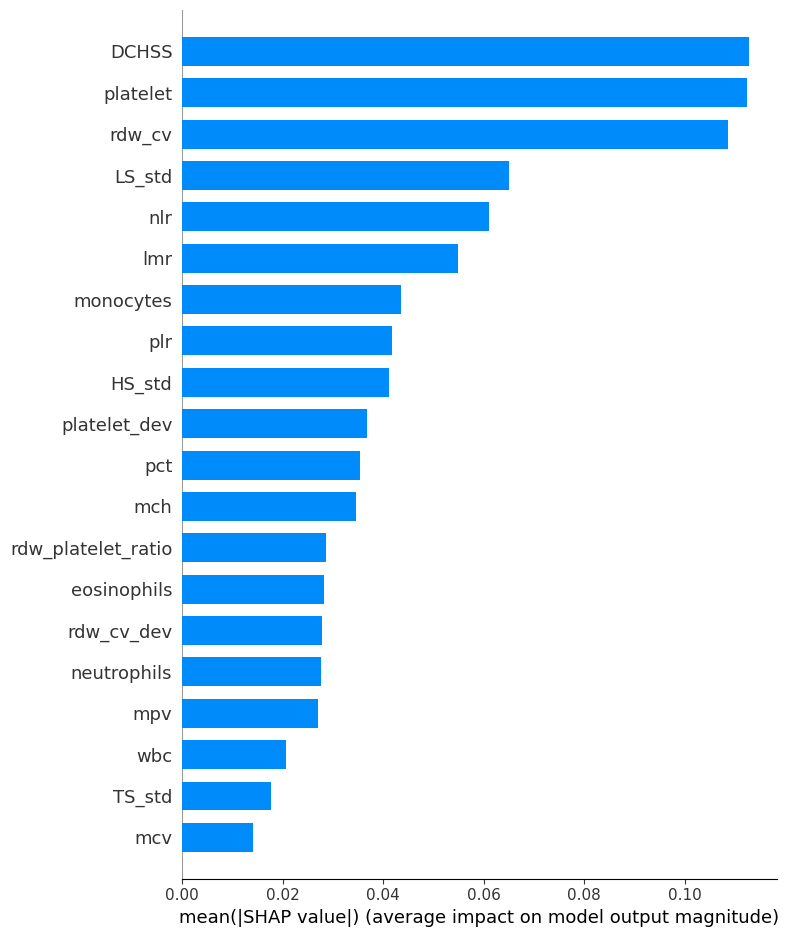


Patient 0 - Actual: 0, Predicted Prob (XGBoost (Full Features)): 0.8172


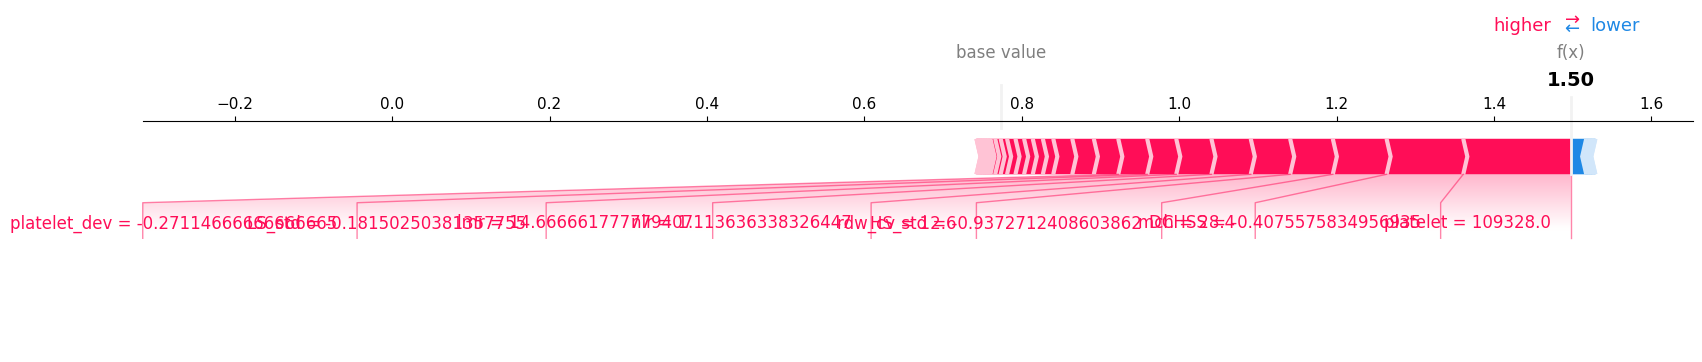


Patient 1 - Actual: 1, Predicted Prob (XGBoost (Full Features)): 0.7848


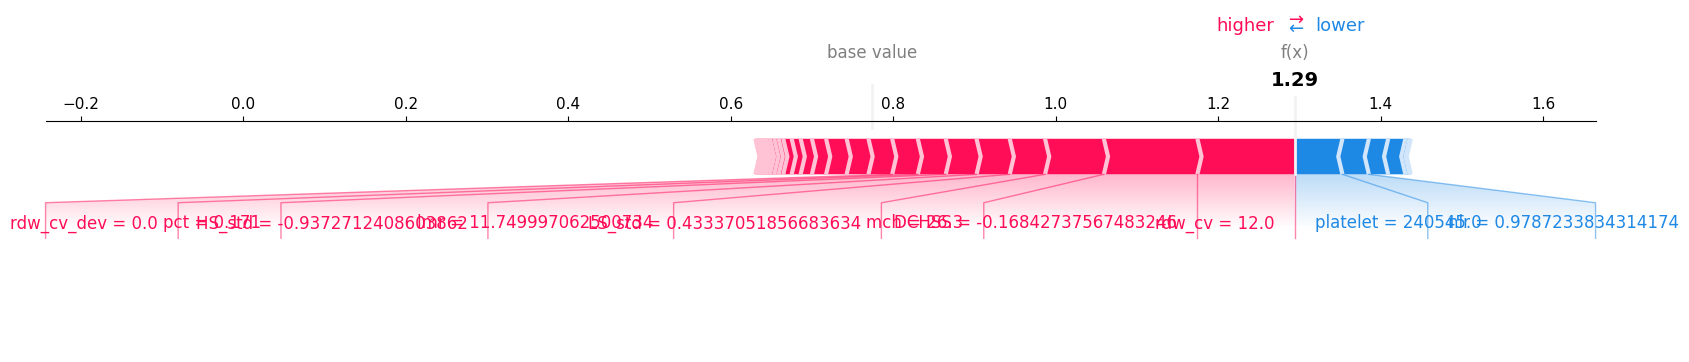


Patient 2 - Actual: 0, Predicted Prob (XGBoost (Full Features)): 0.7520


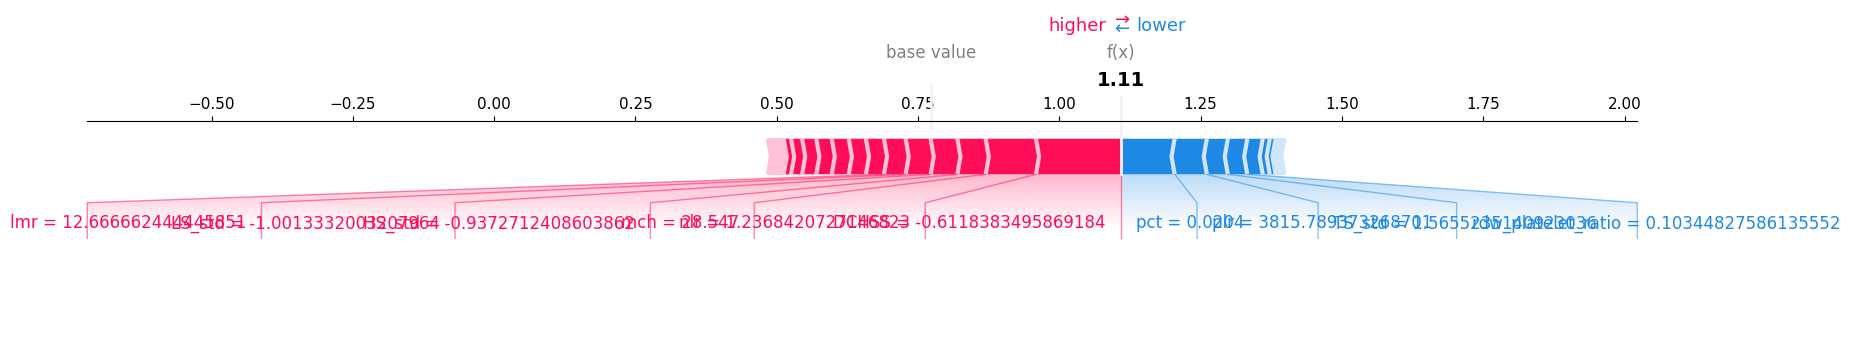

In [95]:
shap.summary_plot(shap_values, X_full_test, plot_type='bar', show=True)

for i in range(3):
    print(f"\nPatient {i} - Actual: {y_test.iloc[i]}, Predicted Prob ({best_candidate_name}): {y_prob_D[i]:.4f}")
    shap.force_plot(explainer.expected_value, shap_values[i], X_full_test.iloc[i],
                     matplotlib=True, show=True)

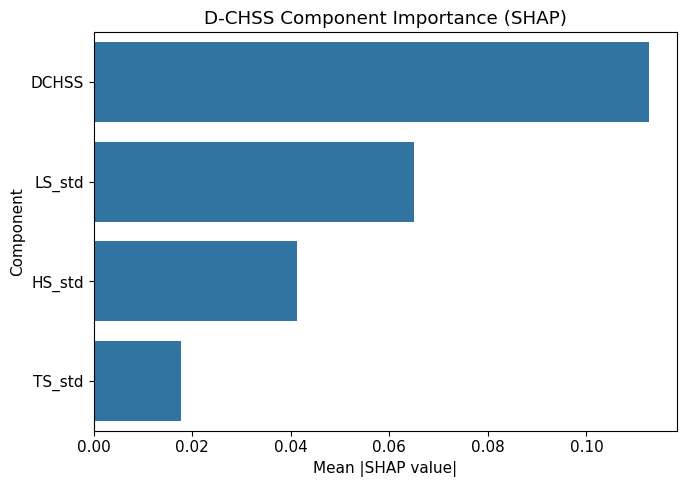

D-CHSS Component Importance:
  Component  Mean |SHAP value|
3     DCHSS           0.112737
1    LS_std           0.065084
2    HS_std           0.041235
0    TS_std           0.017627

Ratio Feature Importance:
        Ratio Feature  Mean |SHAP value|
0                 nlr           0.061030
2                 lmr           0.054981
1                 plr           0.041783
4  rdw_platelet_ratio           0.028716
3       pdw_mpv_ratio           0.008628


In [96]:
component_cols_idx = [X_full_test.columns.get_loc(c) for c in DCHSS_COMPONENT_FEATURES]
mean_abs_shap_components = np.abs(shap_values[:, component_cols_idx]).mean(axis=0)

component_importance_df = pd.DataFrame({
    'Component': DCHSS_COMPONENT_FEATURES,
    'Mean |SHAP value|': mean_abs_shap_components
}).sort_values('Mean |SHAP value|', ascending=False)

ratio_cols_idx = [X_full_test.columns.get_loc(c) for c in RATIO_FEATURES]
mean_abs_shap_ratios = np.abs(shap_values[:, ratio_cols_idx]).mean(axis=0)

ratio_importance_df = pd.DataFrame({
    'Ratio Feature': RATIO_FEATURES,
    'Mean |SHAP value|': mean_abs_shap_ratios
}).sort_values('Mean |SHAP value|', ascending=False)

plt.figure(figsize=(7, 5))
sns.barplot(x='Mean |SHAP value|', y='Component', data=component_importance_df)
plt.title("D-CHSS Component Importance (SHAP)")
plt.tight_layout()
plt.show()

print("D-CHSS Component Importance:")
print(component_importance_df)
print("\nRatio Feature Importance:")
print(ratio_importance_df)

In [97]:
explainer_A = shap.TreeExplainer(model_A)
shap_values_A = explainer_A.shap_values(X_raw_test)
mean_abs_shap_raw = np.abs(shap_values_A).mean(axis=0)

raw_importance_df = pd.DataFrame({
    'Feature': CBC_FEATURES,
    'Mean |SHAP value|': mean_abs_shap_raw
}).sort_values('Mean |SHAP value|', ascending=False)

explainer_C = shap.TreeExplainer(model_C)
shap_values_C = explainer_C.shap_values(X_dchss_test)
mean_abs_shap_dchss = np.abs(shap_values_C).mean(axis=0)

dchss_importance_df = pd.DataFrame({
    'Feature': DCHSS_COMPONENT_FEATURES,
    'Mean |SHAP value|': mean_abs_shap_dchss
}).sort_values('Mean |SHAP value|', ascending=False)

print("Raw CBC Feature Importance (SHAP):")
print(raw_importance_df)
print("\nD-CHSS Component Feature Importance (SHAP):")
print(dchss_importance_df)

Raw CBC Feature Importance (SHAP):
        Feature  Mean |SHAP value|
11     platelet           0.204509
10       rdw_cv           0.157384
1   neutrophils           0.119052
3     monocytes           0.084248
14          pct           0.079153
8           mch           0.042621
4   eosinophils           0.038049
15          wbc           0.033892
5           rbc           0.026753
12          mpv           0.024002
7           mcv           0.022386
2   lymphocytes           0.017658
13          pdw           0.015917
6           hct           0.015157
9          mchc           0.012458
0    hemoglobin           0.009266

D-CHSS Component Feature Importance (SHAP):
  Feature  Mean |SHAP value|
3   DCHSS           0.220657
1  LS_std           0.156063
0  TS_std           0.105646
2  HS_std           0.068047


In [98]:
both_correct = np.sum((y_pred_best_baseline == y_test.values) & (y_pred_D == y_test.values))
baseline_only = np.sum((y_pred_best_baseline == y_test.values) & (y_pred_D != y_test.values))
dchss_only = np.sum((y_pred_best_baseline != y_test.values) & (y_pred_D == y_test.values))
both_wrong = np.sum((y_pred_best_baseline != y_test.values) & (y_pred_D != y_test.values))

contingency_table = [[both_correct, baseline_only], [dchss_only, both_wrong]]

print("McNemar Contingency Table:")
print(pd.DataFrame(contingency_table,
                    index=['Baseline Correct', 'Baseline Wrong'],
                    columns=['Final Model Correct', 'Final Model Wrong']))

mcnemar_result = mcnemar(contingency_table, exact=True)
print(f"\nMcNemar statistic: {mcnemar_result.statistic:.4f}")
print(f"p-value: {mcnemar_result.pvalue:.6f}")

McNemar Contingency Table:
                  Final Model Correct  Final Model Wrong
Baseline Correct                  223                  7
Baseline Wrong                     10                 63

McNemar statistic: 7.0000
p-value: 0.629059


In [99]:
def dchss_cv_evaluation(df_train_full, y_train_full, model_template, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    fold_metrics = {'Accuracy': [], 'Precision': [], 'Recall': [], 'F1': [], 'ROC-AUC': []}

    df_train_full = df_train_full.reset_index(drop=True)
    y_train_full = y_train_full.reset_index(drop=True)

    for tr_idx, val_idx in skf.split(df_train_full, y_train_full):
        fold_train = df_train_full.iloc[tr_idx].copy()
        fold_val = df_train_full.iloc[val_idx].copy()
        y_ft = y_train_full.iloc[tr_idx]
        y_fv = y_train_full.iloc[val_idx]

        # Re-fit component scaler and D-CHSS weights WITHIN this fold only
        fold_scaler = StandardScaler()
        fold_scaler.fit(fold_train[['TS_raw', 'LS_raw', 'HS_raw']])
        tr_std = fold_scaler.transform(fold_train[['TS_raw', 'LS_raw', 'HS_raw']])
        va_std = fold_scaler.transform(fold_val[['TS_raw', 'LS_raw', 'HS_raw']])

        fold_train['TS_std'], fold_train['LS_std'], fold_train['HS_std'] = tr_std[:, 0], tr_std[:, 1], tr_std[:, 2]
        fold_val['TS_std'], fold_val['LS_std'], fold_val['HS_std'] = va_std[:, 0], va_std[:, 1], va_std[:, 2]

        fold_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        fold_lr.fit(fold_train[['TS_std', 'LS_std', 'HS_std']], y_ft)
        fc = np.abs(fold_lr.coef_[0])
        fw = fc / fc.sum()

        fold_train['DCHSS'] = fw[0]*fold_train['TS_std'] + fw[1]*fold_train['LS_std'] + fw[2]*fold_train['HS_std']
        fold_val['DCHSS'] = fw[0]*fold_val['TS_std'] + fw[1]*fold_val['LS_std'] + fw[2]*fold_val['HS_std']

        fold_model = clone(model_template)
        fold_model.fit(fold_train[FULL_FEATURES], y_ft)

        fp = fold_model.predict(fold_val[FULL_FEATURES])
        fpb = fold_model.predict_proba(fold_val[FULL_FEATURES])[:, 1]

        fold_metrics['Accuracy'].append(accuracy_score(y_fv, fp))
        fold_metrics['Precision'].append(precision_score(y_fv, fp, zero_division=0))
        fold_metrics['Recall'].append(recall_score(y_fv, fp, zero_division=0))
        fold_metrics['F1'].append(f1_score(y_fv, fp, zero_division=0))
        fold_metrics['ROC-AUC'].append(roc_auc_score(y_fv, fpb))

    return fold_metrics

cv_fold_metrics = dchss_cv_evaluation(df_train, y_train, final_dchss_xgb_model, n_splits=5)

print(f"5-Fold Stratified CV Results ({best_candidate_name}, Leakage-Safe):")
for metric, values in cv_fold_metrics.items():
    print(f"  {metric}: {np.mean(values):.4f} +/- {np.std(values):.4f}")

5-Fold Stratified CV Results (XGBoost (Full Features), Leakage-Safe):
  Accuracy: 0.7699 +/- 0.0260
  Precision: 0.7586 +/- 0.0249
  Recall: 0.9758 +/- 0.0067
  F1: 0.8533 +/- 0.0142
  ROC-AUC: 0.6956 +/- 0.0542


=== FINAL HOLD-OUT TEST PERFORMANCE (XGBoost (Full Features), Optimal Threshold) ===

Accuracy: 0.7690
Precision: 0.7674
Recall: 0.9519
Specificity: 0.3684
F1: 0.8498
ROC-AUC: 0.6847
PR-AUC: 0.7997
MCC: 0.4179


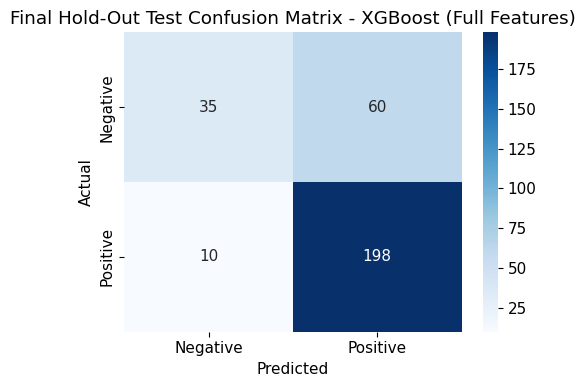

In [100]:
print(f"=== FINAL HOLD-OUT TEST PERFORMANCE ({best_candidate_name}, Optimal Threshold) ===\n")
for k, v in metrics_D.items():
    print(f"{k}: {v:.4f}")

plot_confusion(y_test, y_pred_D, f"Final Hold-Out Test Confusion Matrix - {best_candidate_name}")

In [101]:
sample_idx = [0, 1]

for idx in sample_idx:
    patient = df_test.iloc[idx]
    print(f"\n================ TEST PATIENT INDEX {idx} ================")
    for p in CBC_FEATURES:
        print(f"  {p}: {patient[p]} -> State: {patient[p+'_state']}, Deviation: {patient[p+'_dev']:.4f}")

    print(f"\nThrombocytopenia Score: raw={patient['TS_raw']:.4f}, std={patient['TS_std']:.4f}")
    print(f"Leukocyte Response Score: raw={patient['LS_raw']:.4f}, std={patient['LS_std']:.4f}")
    print(f"Hemoconcentration Score: raw={patient['HS_raw']:.4f}, std={patient['HS_std']:.4f}")
    print(f"NLR: {patient['nlr']:.4f}, PLR: {patient['plr']:.4f}, LMR: {patient['lmr']:.4f}")
    print(f"D-CHSS: {patient['DCHSS']:.4f}")
    print(f"Risk Group: {patient['risk_group']}")
    print(f"Predicted Dengue Probability: {y_prob_D[idx]:.4f}")
    print(f"Classification Threshold Used: {best_thresh:.4f}")
    print(f"Final Prediction: {'Positive' if y_pred_D[idx]==1 else 'Negative'}")
    print(f"Actual Result: {'Positive' if y_test.iloc[idx]==1 else 'Negative'}")

print("\nNOTE: Research demonstration only - NOT a medical diagnosis tool.")


================ TEST PATIENT INDEX 0 ================
  hemoglobin: 16.6 -> State: NORMAL, Deviation: 0.0000
  neutrophils: 49.0 -> State: NORMAL, Deviation: 0.0000
  lymphocytes: 44.0 -> State: HIGH, Deviation: 0.1000
  monocytes: 3.0 -> State: NORMAL, Deviation: 0.0000
  eosinophils: 4.0 -> State: NORMAL, Deviation: 0.0000
  rbc: 5.0 -> State: NORMAL, Deviation: 0.0000
  hct: 41.68 -> State: NORMAL, Deviation: 0.0000
  mcv: 92.2 -> State: NORMAL, Deviation: 0.0000
  mch: 28.4 -> State: NORMAL, Deviation: 0.0000
  mchc: 32.2 -> State: NORMAL, Deviation: 0.0000
  rdw_cv: 12.6 -> State: NORMAL, Deviation: 0.0000
  platelet: 109328.0 -> State: LOW, Deviation: -0.2711
  mpv: 10.49 -> State: NORMAL, Deviation: 0.0000
  pdw: 15.0 -> State: NORMAL, Deviation: 0.0000
  pct: 0.18 -> State: NORMAL, Deviation: 0.0000
  wbc: 6849.0 -> State: NORMAL, Deviation: 0.0000

Thrombocytopenia Score: raw=0.0678, std=-0.2474
Leukocyte Response Score: raw=0.0200, std=-0.1815
Hemoconcentration Score: raw=0

In [102]:
final_results = baseline_results_df.copy()
final_results.loc['Deviation + XGBoost'] = metrics_B
final_results.loc['D-CHSS + XGBoost'] = metrics_C
final_results.loc[f'Final Proposed ({best_candidate_name})'] = metrics_D

final_results = final_results[['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC-AUC', 'PR-AUC', 'MCC']]
final_results.round(4)

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC
Logistic Regression,0.6172,0.7323,0.6971,0.4421,0.7143,0.6216,0.7478,0.1357
Decision Tree,0.7492,0.7619,0.9231,0.3684,0.8348,0.6334,0.7488,0.3614
Random Forest,0.7591,0.7528,0.9663,0.3053,0.8463,0.6625,0.7679,0.3894
SVM,0.7195,0.7173,0.9760,0.1579,0.8269,0.6584,0.7816,0.2501
XGBoost,0.7591,0.7473,0.9808,0.2737,0.8482,0.6584,0.7747,0.3952
Deviation + XGBoost,0.7591,0.7491,0.9760,0.2842,0.8476,0.6326,0.7528,0.3927
D-CHSS + XGBoost,0.7426,0.7372,0.9712,0.2421,0.8382,0.6041,0.7219,0.3363
Final Proposed (XGBoost (Full Features)),0.7690,0.7674,0.9519,0.3684,0.8498,0.6847,0.7997,0.4179


In [103]:
final_ablation_table = pd.DataFrame({
    'Feature Strategy': ['Raw CBC', 'Deviation', 'D-CHSS', 'Raw + Deviation + D-CHSS + Ratios'],
    'Model': ['XGBoost', 'XGBoost', 'XGBoost', best_candidate_name],
    'ROC-AUC': [metrics_A['ROC-AUC'], metrics_B['ROC-AUC'], metrics_C['ROC-AUC'], metrics_D['ROC-AUC']],
    'F1': [metrics_A['F1'], metrics_B['F1'], metrics_C['F1'], metrics_D['F1']],
    'Recall': [metrics_A['Recall'], metrics_B['Recall'], metrics_C['Recall'], metrics_D['Recall']]
})

final_ablation_table.round(4)

,Feature Strategy,Model,ROC-AUC,F1,Recall
0,Raw CBC,XGBoost,0.6531,0.8518,0.9808
1,Deviation,XGBoost,0.6326,0.8476,0.9760
2,D-CHSS,XGBoost,0.6041,0.8382,0.9712
3,Raw + Deviation + D-CHSS + Ratios,XGBoost (Full Features),0.6847,0.8498,0.9519


In [104]:
best_baseline_auc = baseline_results_df.loc[best_baseline_name, 'ROC-AUC']
dchss_auc = metrics_D['ROC-AUC']
raw_auc = metrics_A['ROC-AUC']

component_names = ['Thrombocytopenia Score', 'Leukocyte Response Score', 'Hemoconcentration Score']
component_weight_values = [w_ts, w_ls, w_hs]
most_informative_component = component_names[int(np.argmax(component_weight_values))]

brier_dchss = brier_scores[best_candidate_name]
calibration_quality = ("well-calibrated" if brier_dchss < 0.20
                        else "moderately calibrated" if brier_dchss < 0.25
                        else "poorly calibrated")

top_raw_feature = raw_importance_df.iloc[0]['Feature']

cv_auc_mean = np.mean(cv_fold_metrics['ROC-AUC'])
cv_auc_std = np.std(cv_fold_metrics['ROC-AUC'])

summary = f"""
=== AUTOMATED RESEARCH SUMMARY (Based on Actual Computed Results) ===

1. Best baseline model: {best_baseline_name} (Test ROC-AUC = {best_baseline_auc:.4f})

2. Final proposed model: {best_candidate_name}
   Test ROC-AUC = {dchss_auc:.4f} vs Raw CBC + XGBoost ROC-AUC = {raw_auc:.4f}.
   {"The proposed feature set (Raw+Deviation+D-CHSS+Ratios) improved performance over raw CBC alone." if dchss_auc > raw_auc else "The proposed feature set did not improve performance over raw CBC alone in this run."}

3. Most informative D-CHSS component: {most_informative_component}
   (w_ts={w_ts:.4f}, w_ls={w_ls:.4f}, w_hs={w_hs:.4f})

4. Calibration: {best_candidate_name} Brier Score = {brier_dchss:.4f} ({calibration_quality}).

5. Decision Curve Analysis plotted comparing Treat-All, Treat-None, best baseline, and {best_candidate_name}.

6. Most important raw CBC parameter (SHAP): {top_raw_feature}

7. Cross-validation stability (5-fold, leakage-safe): ROC-AUC = {cv_auc_mean:.4f} +/- {cv_auc_std:.4f}

8. Final classification threshold (learned from training CV, Youden's J): {best_thresh:.4f}
   (used instead of default 0.5 to balance sensitivity and specificity)

This summary is generated directly from actual computed results of this notebook run.
"""
print(summary)


=== AUTOMATED RESEARCH SUMMARY (Based on Actual Computed Results) ===

1. Best baseline model: Random Forest (Test ROC-AUC = 0.6625)

2. Final proposed model: XGBoost (Full Features)
   Test ROC-AUC = 0.6847 vs Raw CBC + XGBoost ROC-AUC = 0.6531.
   The proposed feature set (Raw+Deviation+D-CHSS+Ratios) improved performance over raw CBC alone.

3. Most informative D-CHSS component: Leukocyte Response Score
   (w_ts=0.1446, w_ls=0.5689, w_hs=0.2865)

4. Calibration: XGBoost (Full Features) Brier Score = 0.1779 (well-calibrated).

5. Decision Curve Analysis plotted comparing Treat-All, Treat-None, best baseline, and XGBoost (Full Features).

6. Most important raw CBC parameter (SHAP): platelet

7. Cross-validation stability (5-fold, leakage-safe): ROC-AUC = 0.6956 +/- 0.0542

8. Final classification threshold (learned from training CV, Youden's J): 0.6207
   (used instead of default 0.5 to balance sensitivity and specificity)

This summary is generated directly from actual computed resu

## Proposed Contributions
1. D-CHSS derived from CBC parameters.
2. Reference-range based deviation representation (winsorized to prevent outlier domination).
3. Three interpretable components: Thrombocytopenia, Leukocyte Response, Hemoconcentration.
4. Literature-supported hematological ratio features (NLR, PLR, LMR, etc.) as supplementary engineering.
5. Training-only learned component weights.
6. Leakage-controlled pipeline, including leakage-safe optimal threshold selection and model selection.
7. Ablation analysis across four feature strategies.
8. Signature-probability consistency analysis.
9. Risk stratification.
10. Calibration analysis.
11. Decision-curve analysis.
12. SHAP explainability.

## How this differs from a standard dengue ML pipeline
A standard pipeline feeds raw CBC values directly into a classifier. D-CHSS additionally:
- converts raw values into clinically normalized, capped deviations using reference ranges,
- aggregates deviations into three interpretable hematological components,
- engineers established hematological ratios from the same raw CBC columns,
- learns the component weights only from training data (no manual weights),
- learns the classification decision threshold and selects the best model architecture using
  training-only cross-validation,
- evaluates the resulting signature for consistency, calibration, and clinical net benefit,
alongside standard predictive performance evaluation.

In [50]:
# from google.colab import files

# artifact = {
#     'model': final_dchss_xgb_model,
#     'model_type': best_candidate_name,
#     'classification_threshold': best_thresh,
#     'reference_ranges': REFERENCE_RANGES,
#     'sex_specific_params': SEX_SPECIFIC_PARAMS,
#     'max_deviation_cap': MAX_DEV,
#     'cbc_features': CBC_FEATURES,
#     'dev_features': DEV_FEATURES,
#     'dchss_component_features': DCHSS_COMPONENT_FEATURES,
#     'ratio_features': RATIO_FEATURES,
#     'full_feature_columns': FULL_FEATURES,
#     'imputer_num': imputer_num,
#     'imputer_cat': imputer_cat,
#     'component_scaler': component_scaler,
#     'weight_logreg': weight_logreg,
#     'dchss_weights': {'w_ts': w_ts, 'w_ls': w_ls, 'w_hs': w_hs},
#     'risk_thresholds': {'low_thresh': low_thresh, 'high_thresh': high_thresh},
#     'gender_mapping': gender_mapping,
#     'result_mapping': result_mapping
# }

# with open('dchss_model.pkl', 'wb') as f:
#     pickle.dump(artifact, f)

# print("Model artifact saved as dchss_model.pkl")
# files.download('dchss_model.pkl')